# SEAVEA Workflow Tutorial (Cirrus, macOS)


The **SEAVEA** (see-vee-uh) Toolkit is an open-source framework that supports **Verification, Validation, and Uncertainty Quantification (VVUQ)** for scientific computing applications. It provides a collection of interoperable tools that help researchers design, execute, and analyse computational experiments at scale, from local machines to High-Performance Computing (HPC) environments.

By combining workflow automation, uncertainty quantification, ensemble execution, and surrogate modelling capabilities, SEAVEA enables researchers to conduct complex simulation studies in a reproducible and efficient manner. The toolkit has been developed to support a wide range of scientific domains, including:

* Climate Science
* Fusion Energy
* Epidemiology
* Migration Modelling
* Aerospace Engineering
* Medicine

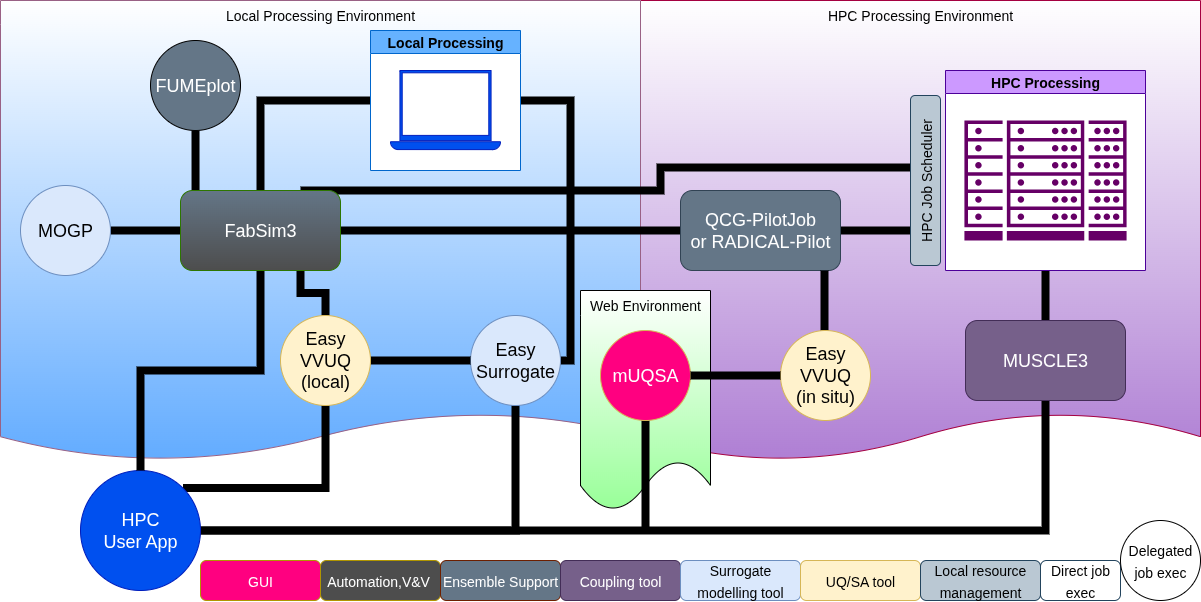

<p align="center">
    <strong>Figure 1.</strong> High-level architecture of the SEAVEA toolkit showing the interaction between local computing resources, HPC systems, workflow automation, uncertainty quantification, and simulation execution tools.
</p>

Figure 1 provides an overview of the SEAVEA ecosystem and how its components work together to support scientific computing workflows. The architecture is divided into a **Local Processing Environment** (left) and an **HPC Processing Environment** (right).

Within the local environment, researchers define simulation experiments, configure uncertain parameters, and perform uncertainty quantification using tools such as **EasyVVUQ**. **FabSim3** acts as the central workflow automation framework, coordinating simulation execution, managing files, and connecting local resources to remote HPC systems.

For large-scale simulation studies, workflows can be executed on HPC resources using **QCG-PilotJob** or **RADICAL-Pilot**, which efficiently manage large ensembles of simulation tasks within a single HPC allocation. These tasks are then scheduled and executed on the HPC cluster.

The broader SEAVEA ecosystem also includes additional components for surrogate modelling (EasySurrogate, MOGP Emulator), multiscale model coupling (MUSCLE3), uncertainty quantification portals (mUQSA), and visualisation (FUMEplot). These components are included in the architecture diagram to illustrate the full capabilities of SEAVEA; however, they are outside the scope of this introductory tutorial. 

## Components Used in this Tutorial

This tutorial focuses on the workflow formed by **EasyVVUQ**, **FabSim3**, and **QCG-PilotJob**, which together enable researchers to define uncertainty studies, automate simulation execution, and efficiently run large ensembles on local or HPC resources.


| Component        | Description                                                                                                                                              |
| ---------------- | -------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **EasyVVUQ**     | Defines uncertain parameters, generates samples, manages simulation campaigns, and performs uncertainty quantification and sensitivity analysis.         |
| **FabSim3**      | Automates workflow execution, file transfer, and job management across local and HPC systems.                                                            |
| **QCG-PilotJob** | Efficiently executes large ensembles of simulation tasks within a single HPC allocation, reducing scheduler overhead and improving resource utilisation. |

## Environment Set-up Instructions

### Prerequisites

Before running this notebook:

- Follow `docs/setup_macos.md`. It creates the `~/seavea` workspace used throughout this notebook.
- Create a Python 3.10 virtual environment and install `requirements.txt`
  (`bash scripts/setup_notebook_env.sh`).
- Install and configure FabSim3, including creation of `machines_user.yml`.
- Install Flee and the FabFlee plugin.
- Confirm that the Mali configuration is available.

> This is the macOS version of the notebook. On Windows, use `seavea-workflow-cirrus_wsl.ipynb`.

### Links

Please refer to the following links for the corresponding components setup to be able to follow this tutorial.

FabSim3 installation (The installation process creates the
required fabsim/deploy/machines_user.yml file) - https://fabsim3.readthedocs.io/en/latest/installation/
<br>
EasyVVUQ installation - https://easyvvuq.readthedocs.io/en/dev/installation.html#id1
<br>
QCG-PilotJob installation - https://qcg-pilotjob.readthedocs.io/en/develop/installation.html
<br>
Flee installation - https://flee.readthedocs.io/en/master/Installation_and_Testing/
<br>
FabFlee Plugin - https://fabsim3.readthedocs.io/en/latest/plugins/

## Tutorial Problem Focus

This tutorial demonstrates how the SEAVEA components work together to support the simulation, validation, uncertainty quantification, and efficient execution of forced-migration models.

The primary demonstration uses the **Mali conflict scenario**, with additional examples from **Burundi, South Sudan, and the Central African Republic**.

The tutorial covers:

- Simulating refugee movements and camp populations using Flee.
- Automating simulation workflows and result collection with FabSim3.
- Comparing predicted camp populations with historical UNHCR data.
- Automatically validating multiple conflict scenarios.
- Investigating uncertain movement assumptions, including `max_move_speed` and `max_walk_speed`.
- Measuring total prediction error.
- Calculating Sobol sensitivity indices with EasyVVUQ.
- Executing simulation ensembles concurrently with QCG-PilotJob.

Together, these components provide an integrated workflow for examining how modelling assumptions affect forced-migration predictions while reducing the effort and computational cost of running large simulation ensembles.

## Table of Contents

- [Environment Set-up Instructions](#environment-set-up-instructions)
  - [Prerequisites](#prerequisites)
  - [Links](#links)
  - [Tutorial Problem Focus](#tutorial-problem-focus)

- [Set-up Instructions](#set-up-instructions)
  - [macOS Setup](#macos-setup)
  - [Workspace Paths](#workspace-paths)
  - [Clone Repositories](#clone-repositories)
  - [SSH Key Setup](#ssh-key-setup)

- [FabSim3 Introduction](#fabsim3-introduction)
  - [Dependencies](#dependencies)
  - [Configure FabSim3](#configure-fabsim3)
  - [Install FabSim3](#install-fabsim3)
  - [Configure machines_user.yml](#configure-machines_useryml)
  - [Add FabSim3 to PATH and PYTHONPATH](#add-fabsim3-to-path-and-pythonpath)

- [Migration Modelling with Flee and FabFlee](#migration-modelling-with-flee-and-fabflee)
  - [Verify Flee and FabFlee](#verify-flee-and-fabflee)
  - [Configure FabFlee Machine Settings](#configure-fabflee-machine-settings)
  - [Install Required Python Modules](#install-required-python-modules)
  - [Inspect the Mali Scenario](#inspect-the-mali-scenario)
  - [Run a Baseline Mali Simulation](#run-a-baseline-mali-simulation)
  - [Note Submitted Job Directory](#note-submitted-job-directory)
  - [Fetch Simulation Results](#fetch-simulation-results)
  - [Plot Simulation Output](#plot-simulation-output)
  - [Compare Predictions with UNHCR Data](#compare-predictions-with-unhcr-data)

- [EasyVVUQ Introduction](#easyvvuq-introduction)
  - [Key Capabilities](#key-capabilities)
  - [Role in the SEAVEA Workflow](#role-in-the-seavea-workflow)
  - [EasyVVUQ Components](#easyvvuq-components)
  - [Workflow Overview](#workflow-overview)
  - [Install EasyVVUQ into FabSim3 Environment](#install-easyvvuq-into-fabsim3-environment)
  - [Import EasyVVUQ and Chaospy](#import-easyvvuq-and-chaospy)
  - [Read FabFlee Uncertainty Configuration](#read-fabflee-uncertainty-configuration)
  - [Parameter Exploration](#parameter-exploration)
  - [Create Chaospy Distributions](#create-chaospy-distributions)
  - [Create EasyVVUQ Sampler](#create-easyvvuq-sampler)
  - [Generate and Execute EasyVVUQ Ensemble](#generate-and-execute-easyvvuq-ensemble)
  - [Inspect Encoded Flee Configurations](#inspect-encoded-flee-configurations)
  - [Decode and Analyse Ensemble Results](#decode-and-analyse-ensemble-results)
  - [Display and Interpret Sensitivity Results](#display-and-interpret-sensitivity-results)

- [QCG-PilotJob: Running Flee Ensembles on Cirrus](#qcg-pilotjob-running-flee-ensembles-on-cirrus)
  - [What QCG-PilotJob Adds](#what-qcg-pilotjob-adds)
  - [HPC Prerequisites](#hpc-prerequisites)

- [Configure Cirrus](#configure-cirrus)
  - [Set up SSH Access to Cirrus](#set-up-ssh-access-to-cirrus)
  - [Log in Once (Multiplexing)](#log-in-once-multiplexing)
  - [Set the Cirrus Variables](#set-the-cirrus-variables)
  - [Add Cirrus to machines_user.yml](#add-cirrus-to-machines_useryml)
  - [Run the Cirrus Connection Check](#run-the-cirrus-connection-check)

- [Run Flee with QCG-PilotJob on Cirrus](#run-flee-with-qcg-pilotjob-on-cirrus)
  - [Configure FabFlee for Cirrus](#configure-fabflee-for-cirrus)
  - [Prepare the Remote Environment](#prepare-the-remote-environment)
  - [Check the Ensemble Inputs](#check-the-ensemble-inputs)
  - [Submit the Ensemble](#submit-the-ensemble)
  - [Wait for the Job](#wait-for-the-job)
  - [Check the Runs on Cirrus](#check-the-runs-on-cirrus)
  - [Fetch the Results](#fetch-the-results)
  - [Compare the Ensemble Runs](#compare-the-ensemble-runs)

# Set-up Instructions



### macOS Setup

Install [Homebrew](https://brew.sh/) if it is not already installed, then install the tools this notebook uses (`rsync` copies Flee to Cirrus later on):

In [1]:
%%bash

brew install git python rsync openssh

==> Downloading Homebrew API data
✔︎ JSON API packages.arm64_golden_gate.jws.json
To reinstall 2.56.0_1, run:
  brew reinstall git
To reinstall 3.15.0_1, run:
  brew reinstall python@3.15
To reinstall 3.5.1, run:
  brew reinstall rsync
To reinstall 10.6p1_1, run:
  brew reinstall openssh


### Workspace Paths

This notebook expects the following layout, which the setup guides in `docs/` create:

```text
~/seavea/
├── SEAVEA-notebooks/
├── FabSim3/
└── flee/
```

**Run the cell below every time you start or restart the kernel**, including when you skip straight to a later section. It defines `FABSIM_ROOT` and `FLEE_ROOT` for the Python cells and exports them for the Bash cells. To use a different location, set the `SEAVEA_WORK` environment variable before starting Jupyter.

In [2]:
import os
import shutil
from pathlib import Path

SEAVEA_WORK = Path(os.environ.get("SEAVEA_WORK", Path.home() / "seavea")).expanduser()
FABSIM_ROOT = SEAVEA_WORK / "FabSim3"
FLEE_ROOT = SEAVEA_WORK / "flee"

# Python used to launch FabSim3: its VirtualEnv if present, otherwise python3 on PATH
_venv_python = FABSIM_ROOT / "VirtualEnv" / "bin" / "python"
FABSIM_PYTHON = Path(os.environ.get("FABSIM_PYTHON")
                     or (_venv_python if _venv_python.exists() else shutil.which("python3")))

# Export for the %%bash cells
os.environ["SEAVEA_WORK"] = str(SEAVEA_WORK)
os.environ["FABSIM_ROOT"] = str(FABSIM_ROOT)
os.environ["FLEE_ROOT"] = str(FLEE_ROOT)
os.environ["FABSIM_PYTHON"] = str(FABSIM_PYTHON)

print("Workspace:", SEAVEA_WORK)
print("FabSim3:  ", FABSIM_ROOT)
print("Flee:     ", FLEE_ROOT)
print("Python:   ", FABSIM_PYTHON)

Workspace: /Users/dianasuleimenova/seavea
FabSim3:   /Users/dianasuleimenova/seavea/FabSim3
Flee:      /Users/dianasuleimenova/seavea/flee
Python:    /Users/dianasuleimenova/seavea/FabSim3/VirtualEnv/bin/python


### Clone the Repositories

Create a workspace directory:

In [3]:
%%bash

mkdir -p "$SEAVEA_WORK"
ls "$SEAVEA_WORK"

FabSim3
flee


Clone the required repositories:

In [4]:
%%bash

cd "$SEAVEA_WORK"
[ -d "$FABSIM_ROOT" ] || git clone https://github.com/djgroen/FabSim3.git "$FABSIM_ROOT"
[ -d "$FLEE_ROOT" ] || git clone https://github.com/djgroen/flee.git "$FLEE_ROOT"
ls "$SEAVEA_WORK"

FabSim3
flee


### Setup ssh key

FabSim3 runs local jobs over SSH to `localhost`. On macOS, first turn on **Remote Login** in *System Settings → General → Sharing*. The cell below then creates an SSH key, allows it for `localhost`, and checks that FabSim3 can log in without a password:

In [5]:
%%bash

if [ ! -f ~/.ssh/id_rsa ]; then
    ssh-keygen -t rsa -N "" -f ~/.ssh/id_rsa
else
    echo "SSH key already exists"
fi
touch ~/.ssh/authorized_keys
grep -qxF "$(cat ~/.ssh/id_rsa.pub)" ~/.ssh/authorized_keys || cat ~/.ssh/id_rsa.pub >> ~/.ssh/authorized_keys
chmod og-wx ~/.ssh/authorized_keys
ssh-keygen -F localhost >/dev/null || ssh-keyscan -H localhost >> ~/.ssh/known_hosts

ssh -o BatchMode=yes localhost 'echo "SSH to localhost works"' \
    || echo "SSH to localhost failed; see the note above this cell."

SSH key already exists


# FabSim3 Introduction

### Dependencies

FabSim3 relies strongly on the following Python modules:

- [Fabric](http://www.fabfile.org) (shown to work with versions 1.5.3 and 1.10.0), 
- [PyYAML](https://pypi.org/project/PyYAML/) (any version), 
- [ruamel.yaml](https://pypi.org/project/ruamel.yaml/)
- [numpy](https://numpy.org/install/) and
- [cryptography](https://pypi.org/project/cryptography/).

In [6]:
%%bash

# Install required Python modules
: "${FABSIM_PYTHON:?Run the Workspace paths cell first}"
"$FABSIM_PYTHON" -m pip install ruamel.yaml rich


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: /Users/dianasuleimenova/seavea/FabSim3/VirtualEnv/bin/python -m pip install --upgrade pip


Alternatively, these dependencies are also marked down in the `requirements.txt` file, as

`fabric3==1.13.1.post1, 
 pyyaml, 
 pytest, 
 pytest-pep8, 
 ruamel.yaml, 
 numpy, 
 cryptography`
 
To install `requirements.txt` into the Python that runs FabSim3, simply run the following:

In [7]:
%%bash

: "${FABSIM_ROOT:?Run the Workspace paths cell first}"
"$FABSIM_PYTHON" -m pip install -r "$FABSIM_ROOT/requirements.txt"


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: /Users/dianasuleimenova/seavea/FabSim3/VirtualEnv/bin/python -m pip install --upgrade pip


### Configure FabSim3
Navigate to the FabSim3 directory:

In [8]:
%%bash

: "${FABSIM_ROOT:?Run the Workspace paths cell first}"
cd "$FABSIM_ROOT"
if [ -f fabsim/deploy/machines_user.yml ]; then
    echo "FabSim3 is already configured: fabsim/deploy/machines_user.yml exists"
else
    python3 configure_fabsim.py
fi

FabSim3 is already configured: fabsim/deploy/machines_user.yml exists


### Intalling FabSim3 

To install [FabSim3](https://github.com/djgroen/FabSim3), clone the repository using:

In [9]:
%%bash

: "${FABSIM_ROOT:?Run the Workspace paths cell first}"
if [ ! -d "$FABSIM_ROOT" ]
then
    git clone https://github.com/djgroen/FabSim3 "$FABSIM_ROOT"
    echo "FabSim3 rep cloned in -> $FABSIM_ROOT"
else
    git -C "$FABSIM_ROOT" pull
    echo "updating FabSim3 rep in -> $FABSIM_ROOT"
fi

Already up to date.
updating FabSim3 rep in -> /Users/dianasuleimenova/seavea/FabSim3


### Configure `machine_user.yml` file

To set personal configurations, copy `machines_user_example.yml` as `machines_user.yml` in the `FabSim3/fabsim/deploy` folder and run the following sequence of commands, which will change `localhost:` configurations:

In [10]:
%%bash
set -e

: "${FABSIM_ROOT:?Run the Workspace paths cell first}"
MACHINES_FILE="$FABSIM_ROOT/fabsim/deploy/machines_user.yml"

if [ ! -f "$MACHINES_FILE" ]; then
    echo "Error: FabSim3 is not configured. Complete the linked installation guide."
    exit 1
fi

echo "FabSim3 configuration found: $MACHINES_FILE"

FabSim3 configuration found: /Users/dianasuleimenova/seavea/FabSim3/fabsim/deploy/machines_user.yml


### Add FabSim3 to your PATH and PYTHONPATH

To add FabSim3 executable file to system `PATH` and setup `PYTHONPATH`:

In [11]:
import os
import sys

sys.path.insert(0, str(FABSIM_ROOT / "fabsim" / "bin"))
sys.path.insert(0, str(FABSIM_ROOT / "fabsim"))
os.environ['PATH'] = str(FABSIM_ROOT / "fabsim" / "bin") + os.pathsep + os.environ['PATH']

# Test if fabsim command is availble
!which fabsim

/Users/dianasuleimenova/seavea/FabSim3/fabsim/bin/fabsim


### Migration Modelling with Flee and FabFlee

In this tutorial, we use two related but separate tools: **Flee** and **FabFlee**.

**Flee** is the migration simulation model. It is an agent-based modelling toolkit written in Python for simulating the movement of displaced people between geographical locations, such as conflict locations, towns, and camps. For more detail, see the [Flee documentation](https://flee.readthedocs.io/en/latest/).

**FabFlee** is not the simulation model itself. It is a FabSim3 plugin that connects FabSim3 to Flee. FabFlee automates the construction, execution, and analysis of Flee simulations by providing ready-made FabSim3 commands for running single simulations, ensembles, replicas, and sensitivity analysis workflows.

In short:

| Tool | Role in this tutorial |
|---|---|
| **Flee** | The agent-based migration model being executed. |
| **FabFlee** | The FabSim3 plugin used to automate and manage Flee simulation workflows. |

We installed Flee earlier by cloning the Flee repository. FabFlee is installed separately as a FabSim3 plugin.

> A FabSim3-based FabFlee plugin provides an environment for researchers and organisations to construct and modify simulations, instantiate and execute multiple runs for different policy decisions, as well as to validate and visualise the obtained results against the existing data.

To install FabFlee, run `install_plugin` function using:

In [12]:
%%bash

export MPLBACKEND=Agg
: "${FABSIM_ROOT:?Run the Workspace paths cell first}"
if [ -d "$FABSIM_ROOT/plugins/FabFlee" ]; then
    echo "FabFlee is already installed: $FABSIM_ROOT/plugins/FabFlee"
else
    "$FABSIM_PYTHON" -X utf8 "$FABSIM_ROOT/fabsim/bin/fabsim" localhost install_plugin:FabFlee
fi

FabFlee is already installed: /Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee


### Verify Flee and FabFlee

This check confirms that the Flee model and its FabSim3 plugin are available before any simulation is launched.

Expected folder layout (recommended):

```text
~/seavea/
├── SEAVEA-notebooks/
├── FabSim3/
└── flee/
```

The paths come from the [Workspace paths](#workspace-paths) cell. If your repositories are stored in a different location, set `SEAVEA_WORK` there.

In [13]:
%%bash
set -e

: "${FABSIM_ROOT:?Run the Workspace paths cell first}"
FABFLEE_ROOT="$FABSIM_ROOT/plugins/FabFlee"

if [ -d "$FLEE_ROOT" ]; then
    echo "Flee found: $FLEE_ROOT"
else
    echo "Flee not found: $FLEE_ROOT"
    exit 1
fi

if [ -d "$FABFLEE_ROOT" ]; then
    echo "FabFlee plugin found: $FABFLEE_ROOT"
else
    echo "FabFlee plugin not found: $FABFLEE_ROOT"
    exit 1
fi

Flee found: /Users/dianasuleimenova/seavea/flee
FabFlee plugin found: /Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee


### Configure FabFlee machine settings

After installing the FabFlee plugin, create a user-specific FabFlee config file from the example:.

In [14]:
%%bash

: "${FABSIM_ROOT:?Run the Workspace paths cell first}"
FABFLEE_ROOT="$FABSIM_ROOT/plugins/FabFlee"

if [ -f "$FABFLEE_ROOT/machines_FabFlee_user.yml" ]; then
    echo "Keeping existing $FABFLEE_ROOT/machines_FabFlee_user.yml"
else
    cp "$FABFLEE_ROOT/machines_FabFlee_user_example.yml" \
       "$FABFLEE_ROOT/machines_FabFlee_user.yml"
fi

Keeping existing /Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/machines_FabFlee_user.yml


Replace the placeholder path with the real location of your cloned Flee repository.

In [15]:
%%bash

: "${FABSIM_ROOT:?Run the Workspace paths cell first}"
FABFLEE_CONFIG="$FABSIM_ROOT/plugins/FabFlee/machines_FabFlee_user.yml"

sed -i.bak "s#<PATH_TO_FLEE>#$FLEE_ROOT#g" "$FABFLEE_CONFIG" && rm -f "$FABFLEE_CONFIG.bak"

Print the updated configuration so users can confirm the Flee path is correct.

In [16]:
%%bash

: "${FABSIM_ROOT:?Run the Workspace paths cell first}"
FABFLEE_CONFIG="$FABSIM_ROOT/plugins/FabFlee/machines_FabFlee_user.yml"

cat "$FABFLEE_CONFIG"

# This is the user personal configuration for job submission and execution for FabFlee plugin
# All given variable here will be override machine settings loaded from (a) FabSim3/deploy/machines.yml and (b) FabSim3/deploy/machines_user.yml 
# 
# Here, you can find some examples for pre-defined remote machines
# All env variable can be modified here and will overwrite setting in machines.yml and machines_user.yml
default:
  UNHCR_uncertainty: False
  FLEE_TYPE_CHECK: False
# required modules for Flee
flee_modules: &FLEE_MODULES
  # list of modules to be loaded on remote machine
  loaded: ["python/3.7.3", "openmpi/4.0.0_gcc620"]
  # list of modules to be unloaded on remote machine
  unloaded: ["python"]


localhost:
  python3_command: "/Users/dianasuleimenova/miniconda3/bin/python3"
  FLEE_TYPE_CHECK: False
  # location of flee in your local PC
  flee_location: "/Users/dianasuleimenova/seavea/flee"

  # location of flare in your local PC
  flare_location: "<PATH_TO_FLARE>"

  # location o

Load the config in Python and display the localhost settings.

In [17]:
from pathlib import Path
import yaml

fabflee_config = FABSIM_ROOT / "plugins" / "FabFlee" / "machines_FabFlee_user.yml"

with open(fabflee_config) as f:
    config = yaml.safe_load(f)

config["localhost"]

{'python3_command': '/Users/dianasuleimenova/miniconda3/bin/python3',
 'FLEE_TYPE_CHECK': False,
 'flee_location': '/Users/dianasuleimenova/seavea/flee',
 'flare_location': '<PATH_TO_FLARE>',
 'cityGraph_location': '~/Codes/citygraph',
 'cityGraph_API_KEY': '5b3ce3597851110001cf62481fe17f28d29945ecb2ca9d2f51f12738',
 'cityGraph_COUNTRY_CODE': '',
 'cityGraph_POPULATION_LIMIT': '',
 'cityGraph_CITIES_LIMIT': ''}

### Installing required python modules for Flee

FabSim3 runs Flee through `ssh localhost` with a minimal `PATH`, so a plain `python3` there is the system Python, which does not have Flee's packages. Install Flee's requirements into the Python used by FabSim3 (`FABSIM_PYTHON`):

In [18]:
%%bash

: "${FABSIM_PYTHON:?Run the Workspace paths cell first}"
"$FABSIM_PYTHON" -m pip install -r "$FLEE_ROOT/requirements.txt"


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: /Users/dianasuleimenova/seavea/FabSim3/VirtualEnv/bin/python -m pip install --upgrade pip


Then tell FabFlee to run Flee with that Python, by adding `python3_command` to the `localhost` block of `machines_FabFlee_user.yml`. Without it, the run produces an empty `out.csv`:

In [19]:
fabflee_config = FABSIM_ROOT / "plugins" / "FabFlee" / "machines_FabFlee_user.yml"
lines = fabflee_config.read_text(encoding="utf-8").splitlines(keepends=True)

# Edit the text rather than re-dumping the YAML, to keep its comments and anchors
start = lines.index("localhost:\n")
end = next(
    (i for i in range(start + 1, len(lines)) if lines[i].strip() and not lines[i].startswith((" ", "#"))),
    len(lines),
)
block = lines[start:end]
setting = f'  python3_command: "{FABSIM_PYTHON}"\n'

if any(line.strip().startswith("python3_command:") for line in block):
    for i in range(start, end):
        if lines[i].strip().startswith("python3_command:"):
            lines[i] = setting
else:
    lines.insert(start + 1, setting)

fabflee_config.write_text("".join(lines), encoding="utf-8")
print(f"localhost python3_command: {FABSIM_PYTHON}")

localhost python3_command: /Users/dianasuleimenova/seavea/FabSim3/VirtualEnv/bin/python


### Inspect the Mali Scenario

The Mali configuration contains the migration network, conflict data, camp locations, simulation settings, and historical observations used for validation.

In [20]:
%%bash
set -e

: "${FABSIM_ROOT:?Run the Workspace paths cell first}"

MALI_SCENARIO="mali2012"
MALI_CONFIG="$FABSIM_ROOT/plugins/FabFlee/config_files/$MALI_SCENARIO"

[ -d "$MALI_CONFIG" ] || { echo "Error: Mali configuration was not found at $MALI_CONFIG"; exit 1; }

echo "Mali configuration: $MALI_CONFIG"
find "$MALI_CONFIG" -maxdepth 2 -type f | sed -n '1,20p'

Mali configuration: /Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/config_files/mali2012
/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/config_files/mali2012/source_data/bf-goudoubo.csv
/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/config_files/mali2012/source_data/mau-mbera.csv
/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/config_files/mali2012/source_data/source-data-unhcr-pdf-reports.txt
/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/config_files/mali2012/source_data/religion.csv
/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/config_files/mali2012/source_data/refugees.csv
/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/config_files/mali2012/source_data/nig-mangaize.csv
/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/config_files/mali2012/source_data/data_layout.csv
/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/config_files/mali2012/source_data/bf-ouagadougou.csv
/Users/dianasuleimenova/seavea/FabSim3/plugins/Fa

### Run a Baseline Mali Simulation

There are 4 different ways to execute multiscale migration simulations in FabFlee:

* Single-model execution
<br>
* Ensemble execution
<br>
* Replica execution
<br>
* Coupled execution

Each method has its unique purpose. The single-model execution can be easily performed on a laptop and instantly provide an overview to users. The ensemble execution may be useful for those who run multiple simulation instances simultaneously. The replica execution could be an interesting option for those who run simulations at once with identical inputs for analysis. The coupled execution can couple migration simulation with conflict evolution models in the context of multiscale uncertainty quantification (UQ).

#### Purposes of Demonstration

To execute FabFlee job on a localhost, execute one of the conflict instances using `flee` function in `FabSim3/plugins/FabFlee/config_files`, such as Mali (mali, simulation period of 300 days), Burundi (burundi, simulation period of 396 days), South Sudan (ssudan, simulation period of 604 days) and Central African Republic (car, simulation period of 820 days). 

For illustration purposes, the conflict scenario of Mali is executed to obtain the simulation output for a simulation period of 50 days, which can be changed up to 300 days.

In [21]:
%%bash

export MPLBACKEND=Agg
cd "$FABSIM_ROOT"
"$FABSIM_PYTHON" -X utf8 fabsim/bin/fabsim localhost sflee:mali2012,simulation_period=50

  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/FabFlee.py", line 1057, in <module>
    from plugins.FabFlee.SA.flee_SA import flee_init_SA
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/SA/flee_SA.py", line 8, in <module>
    import chaospy as cp
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/FabFlee.py", line 1072, in <module>
    from plugins.FabFlee.vis.flee_geo import *
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/vis/flee_geo.py", line 8, in <module>
    import plotly.express as px
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/FabFlee.py", line 1086, in <module>
    from plugins.FabFlee.VVP.flee_vvp import flee_init_vvp_LoR
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/VVP/flee_vvp.py", line 21, in <module>
    import easyvvuq as uq


[loading plugin] FabFlee ...
Error: failed to import settings module flee_SA
<class 'ModuleNotFoundError'>
ModuleNotFoundError("No module named 'chaospy'")
The FabFlee flee_SA functionalities are not imported as a result.
Error: failed to import settings module flee_vis
<class 'ModuleNotFoundError'>
ModuleNotFoundError("No module named 'plotly'")
The FabFlee flee_vis functionalities are not imported as a result.
Error: failed to import settings module flee_vvp
<class 'ModuleNotFoundError'>
ModuleNotFoundError("No module named 'easyvvuq'")
The FabFlee flee_vvp functionalities are not imported as a result.
[Executing task] sflee
calling task sflee from plugin FabFlee
╭─────────────── New/Updated environment variables from FabFlee plugin ────────────────╮
│ env :                                                                                │
│   --- python3_command : python3                                                      │
│   +++ python3_command : /Users/dianasuleimenova/seavea/Fa

YAML file: simsetting.yml
YAML: {'log_levels': {'agent': 1, 'camp': 0, 'init': 0, 'link': 1, 'conflict': 0, 'granularity': 'location'}, 'spawn_rules': {'take_from_population': False, 'conflict_spawn_decay': [1.0, 1.0, 1.0, 0.5, 0.1], 'insert_day0': True}, 'move_rules': {'max_move_speed': 200.0, 'max_walk_speed': 35.0, 'foreign_weight': 1.0, 'camp_weight': 5.0, 'awareness_level': 1, 'capacity_buffer': 0.75, 'conflict_weight': 0.25, 'conflict_movechance': 1.0, 'camp_movechance': 0.001, 'default_movechance': 0.3, 'capacity_scaling': 1.0, 'avoid_short_stints': False, 'start_on_foot': False, 'weight_power': 1.0}, 'optimisations': {'hasten': 10}}
Take from population? False
Spawn decay set to: [1.0, 1.0, 1.0, 0.5, 0.1], with interval 30
INFO: Fixed Route Generation for Locations: False
Move rules set to: {'FloodRulesEnabled': False, 'FloodForecaster': False, 'flood_forecaster_timescale': 0, 'MaxMoveSpeed': 200.0, 'MaxWalkSpeed': 35.0, 'MaxCrossingSpeed': 20.0, 'ForeignWeight': 1.0, 'CampWeig

[local] ssh -Y -p 22 dianasuleimenova@localhost 'cd /Users/dianasuleimenova/seavea/FabSim3/localhost_exe/FabSim/results/mali2012_localhost_1 && true &&  /Users/dianasuleimenova/seavea/FabSim3/localhost_exe/FabSim/results/mali2012_localhost_1/mali2012_localhost_1.sh'
Use fabsim localhost fetch_results to copy the results back to local machine!
submitted job script = 
['/Users/dianasuleimenova/seavea/FabSim3/localhost_exe/FabSim/results/mali2012_localhost_1/mali2012_localhost_1.sh']


### Note the Submitted Job Directory

FabSim3 prints the path of the generated job script when it submits a run. Keep this path because it identifies the run that was executed.

Example:
```bash
Submitted job script:
/home/YOUR_USERNAME/seavea/FabSim3/localhost_exe/FabSim/results/mali2012_localhost_1/mali2012_localhost_1.sh
```

The run directory is the parent folder of that script:

```bash
/home/YOUR_USERNAME/seavea/FabSim3/localhost_exe/FabSim/results/mali2012_localhost_1
```

After fetching results, the corresponding local results directory is usually:

```bash
/home/YOUR_USERNAME/seavea/FabSim3/results/mali2012_localhost_1
```

So for later plotting, use the local fetched results path, not the job script path:

In [22]:
from pathlib import Path
import os

# The run that was just submitted is the newest Mali job directory.
job_dirs = sorted(
    (
        path
        for path in (FABSIM_ROOT / "localhost_exe" / "FabSim" / "results").glob("mali2012_localhost_*")
        if "_SA_" not in path.name
    ),
    key=lambda path: path.stat().st_mtime,
)

if not job_dirs:
    raise FileNotFoundError("No Mali job directory found. Run the baseline simulation first.")

RUN_NAME = job_dirs[-1].name
RESULT_DIR = FABSIM_ROOT / "results" / RUN_NAME

# Export for the fetch cell below
os.environ["RUN_NAME"] = RUN_NAME

print("Run name:", RUN_NAME)
RESULT_DIR

Run name: mali2012_localhost_1


PosixPath('/Users/dianasuleimenova/seavea/FabSim3/results/mali2012_localhost_1')

So yes: keep track of mali2012_localhost_1, but later code should usually use:

#### Fetching the simulation results to `FabSim3/results` directory

After the job has finished, a message will be printed indicating where the output data resides. To copy the results of the new run to the `FabSim3/results` directory, simply execute the command below. The `regex` argument limits the copy to the run identified above (`RUN_NAME`); without it, `fetch_results` copies every run in `localhost_exe`, which can be many gigabytes:

In [23]:
%%bash

: "${RUN_NAME:?Run the cell that sets RUN_NAME first}"

export MPLBACKEND=Agg
cd "$FABSIM_ROOT"
"$FABSIM_PYTHON" -X utf8 fabsim/bin/fabsim localhost "fetch_results:regex=$RUN_NAME"

  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/FabFlee.py", line 1057, in <module>
    from plugins.FabFlee.SA.flee_SA import flee_init_SA
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/SA/flee_SA.py", line 8, in <module>
    import chaospy as cp
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/FabFlee.py", line 1072, in <module>
    from plugins.FabFlee.vis.flee_geo import *
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/vis/flee_geo.py", line 8, in <module>
    import plotly.express as px
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/FabFlee.py", line 1086, in <module>
    from plugins.FabFlee.VVP.flee_vvp import flee_init_vvp_LoR
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/VVP/flee_vvp.py", line 21, in <module>
    import easyvvuq as uq


receiving file list ... done
mali2012_localhost_1/
mali2012_localhost_1/agents.out.0
mali2012_localhost_1/env.log
mali2012_localhost_1/env.yml
mali2012_localhost_1/links.out.0
mali2012_localhost_1/mali2012_localhost_1.sh
mali2012_localhost_1/out.csv

sent 20.54K bytes  received 1.12M bytes  759.11K bytes/sec
total size is 10.74M  speedup is 9.44
[loading plugin] FabFlee ...
Error: failed to import settings module flee_SA
<class 'ModuleNotFoundError'>
ModuleNotFoundError("No module named 'chaospy'")
The FabFlee flee_SA functionalities are not imported as a result.
Error: failed to import settings module flee_vis
<class 'ModuleNotFoundError'>
ModuleNotFoundError("No module named 'plotly'")
The FabFlee flee_vis functionalities are not imported as a result.
Error: failed to import settings module flee_vvp
<class 'ModuleNotFoundError'>
ModuleNotFoundError("No module named 'easyvvuq'")
The FabFlee flee_vvp functionalities are not imported as a result.
[Executing task] fetch_results
[local] r

### Plotting the simulation output

After fetching the simulation results, analyse and interpret simulation output by plotting graphs for individual camps comparing simulation output and UNHCR data, as well as average relative difference graph for the simulated conflict situation.

In [24]:
%%bash

export MPLBACKEND=Agg
: "${FABSIM_ROOT:?Run the Workspace paths cell first}"
: "${RUN_NAME:?Run the cell that sets RUN_NAME first}"
cd "$FABSIM_ROOT"

if [ ! -s "results/$RUN_NAME/out.csv" ]; then
    echo "results/$RUN_NAME/out.csv is empty, so the Flee run failed."
    echo "Run the 'Installing required python modules for Flee' cells, then rerun the simulation."
    exit 1
fi

"$FABSIM_PYTHON" -X utf8 fabsim/bin/fabsim localhost "plot_output:${RUN_NAME},out"

  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/FabFlee.py", line 1057, in <module>
    from plugins.FabFlee.SA.flee_SA import flee_init_SA
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/SA/flee_SA.py", line 8, in <module>
    import chaospy as cp
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/FabFlee.py", line 1072, in <module>
    from plugins.FabFlee.vis.flee_geo import *
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/vis/flee_geo.py", line 8, in <module>
    import plotly.express as px
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/FabFlee.py", line 1086, in <module>
    from plugins.FabFlee.VVP.flee_vvp import flee_init_vvp_LoR
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/VVP/flee_vvp.py", line 21, in <module>
    import easyvvuq as uq


[loading plugin] FabFlee ...
Error: failed to import settings module flee_SA
<class 'ModuleNotFoundError'>
ModuleNotFoundError("No module named 'chaospy'")
The FabFlee flee_SA functionalities are not imported as a result.
Error: failed to import settings module flee_vis
<class 'ModuleNotFoundError'>
ModuleNotFoundError("No module named 'plotly'")
The FabFlee flee_vis functionalities are not imported as a result.
Error: failed to import settings module flee_vvp
<class 'ModuleNotFoundError'>
ModuleNotFoundError("No module named 'easyvvuq'")
The FabFlee flee_vvp functionalities are not imported as a result.
[Executing task] plot_output
calling task plot_output from plugin FabFlee
╭─────────────── New/Updated environment variables from FabFlee plugin ────────────────╮
│ env :                                                                                │
│   --- python3_command : python3                                                      │
│   +++ python3_command : /Users/dianasuleimeno

To list generated plots, run the following command

In [25]:
%%bash
: "${FABSIM_ROOT:?Run the Workspace paths cell first}"
FABSIM_RESULTS="${FABSIM_RESULTS:-$FABSIM_ROOT/results}"
SCENARIO="${SCENARIO:-mali2012}"
MACHINE="${MACHINE:-localhost}"

# env -u CLICOLOR_FORCE stops ls from adding colour codes to the path
RESULT_DIR=$(env -u CLICOLOR_FORCE ls -1td "$FABSIM_RESULTS"/"${SCENARIO}_${MACHINE}"_* 2>/dev/null | head -n 1)

if [ -z "$RESULT_DIR" ]; then
  echo "No result directory found for ${SCENARIO}_${MACHINE}_* in $FABSIM_RESULTS"
  exit 1
fi

echo "Latest result: $RESULT_DIR"

if [ -d "$RESULT_DIR/out" ]; then
  find "$RESULT_DIR/out" -maxdepth 1 -type f
else
  echo "No out directory found in $RESULT_DIR"
fi

Latest result: /Users/dianasuleimenova/seavea/FabSim3/results/mali2012_localhost_1


In [26]:
%%bash
: "${FABSIM_ROOT:?Run the Workspace paths cell first}"
FABSIM_RESULTS="${FABSIM_RESULTS:-$FABSIM_ROOT/results}"
SCENARIO="${SCENARIO:-mali2012}"
MACHINE="${MACHINE:-localhost}"

# env -u CLICOLOR_FORCE stops ls from adding colour codes to the path
RESULT_DIR=$(env -u CLICOLOR_FORCE ls -1td "$FABSIM_RESULTS"/"${SCENARIO}_${MACHINE}"_* 2>/dev/null | head -n 1)

if [ -z "$RESULT_DIR" ]; then
  echo "No result directory found matching: ${SCENARIO}_${MACHINE}_*"
  echo "Searched in: $FABSIM_RESULTS"
  exit 1
fi

echo "Result directory: $RESULT_DIR"

if [ ! -d "$RESULT_DIR/out" ]; then
  echo "No output directory found: $RESULT_DIR/out"
  exit 1
fi

echo "Output contents:"
find "$RESULT_DIR/out" -type f

Result directory: /Users/dianasuleimenova/seavea/FabSim3/results/mali2012_localhost_1
Output contents:
/Users/dianasuleimenova/seavea/FabSim3/results/mali2012_localhost_1/out/camps/Fassala-Mbera.png
/Users/dianasuleimenova/seavea/FabSim3/results/mali2012_localhost_1/out/camps/Tabareybarey.png
/Users/dianasuleimenova/seavea/FabSim3/results/mali2012_localhost_1/out/camps/Mentao.png
/Users/dianasuleimenova/seavea/FabSim3/results/mali2012_localhost_1/out/camps/Abala.png
/Users/dianasuleimenova/seavea/FabSim3/results/mali2012_localhost_1/out/camps/Niamey.png
/Users/dianasuleimenova/seavea/FabSim3/results/mali2012_localhost_1/out/camps/Mangaize.png
/Users/dianasuleimenova/seavea/FabSim3/results/mali2012_localhost_1/out/camps/Bobo-Dioulasso.png
/Users/dianasuleimenova/seavea/FabSim3/results/mali2012_localhost_1/out/numagents/numagents.png
/Users/dianasuleimenova/seavea/FabSim3/results/mali2012_localhost_1/out/errors/error_comparison.png
/Users/dianasuleimenova/seavea/FabSim3/results/mali2012_

To view generated plots, simply run:

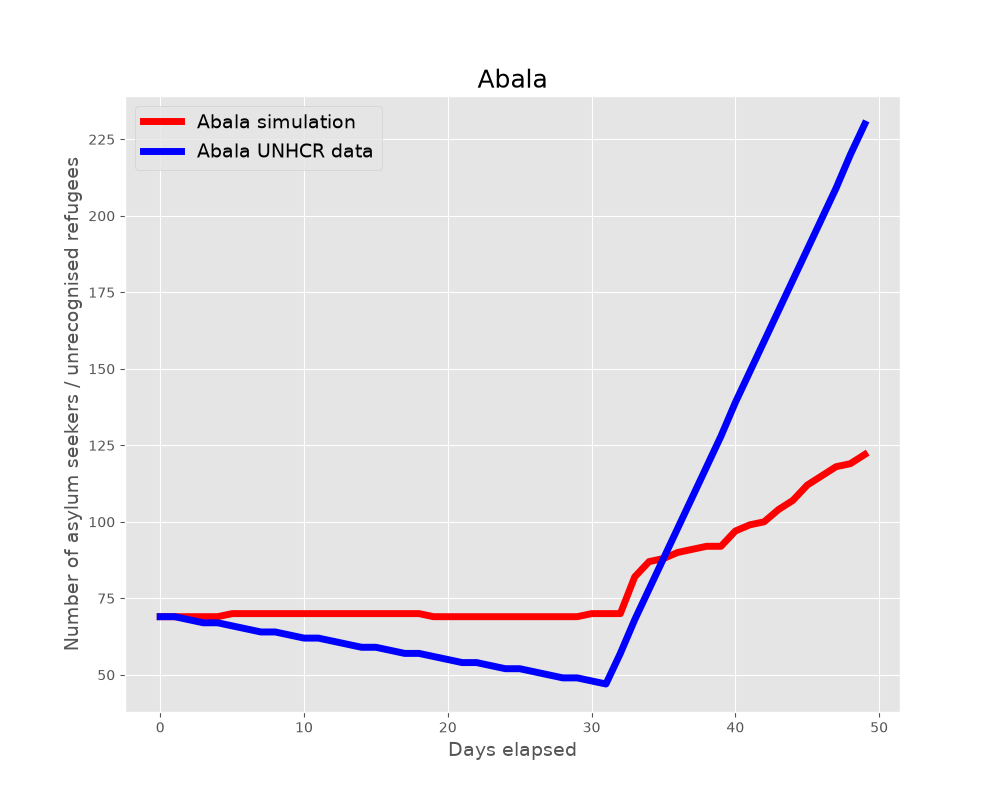

In [27]:
from pathlib import Path
from IPython.display import Image, display

# Change this to one of the result directories printed above
RESULT_DIR = FABSIM_ROOT / "results" / "mali2012_localhost_1"

# Change this if you want a different camp/image
IMAGE_PATH = RESULT_DIR / "out" / "camps" / "Abala.png"

display(Image(filename=str(IMAGE_PATH)))

### Compare Predictions with UNHCR Data

FabFlee compares simulated populations at individual camps with historical UNHCR observations. The generated plots show camp-level agreement and prediction error over time.

In [28]:
%%bash
set -e

export MPLBACKEND=Agg

: "${FABSIM_ROOT:?Run the Workspace paths cell first}"

LATEST_RESULT=$(
    env -u CLICOLOR_FORCE ls -1td "$FABSIM_ROOT"/results/mali2012_localhost_* 2>/dev/null |
    grep -v "_SA_" |
    head -n 1 || true
)

if [ -z "$LATEST_RESULT" ]; then
    echo "No fetched Mali result found. Run and fetch the baseline first."
    exit 1
fi

RUN_NAME="$(basename "$LATEST_RESULT")"

cd "$FABSIM_ROOT"

echo "Generating validation plots for: $RUN_NAME"

"$FABSIM_PYTHON" -X utf8 ./fabsim/bin/fabsim \
    localhost "plot_output:${RUN_NAME},out"

Generating validation plots for: mali2012_localhost_1


  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/FabFlee.py", line 1057, in <module>
    from plugins.FabFlee.SA.flee_SA import flee_init_SA
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/SA/flee_SA.py", line 8, in <module>
    import chaospy as cp
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/FabFlee.py", line 1072, in <module>
    from plugins.FabFlee.vis.flee_geo import *
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/vis/flee_geo.py", line 8, in <module>
    import plotly.express as px
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/FabFlee.py", line 1086, in <module>
    from plugins.FabFlee.VVP.flee_vvp import flee_init_vvp_LoR
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/VVP/flee_vvp.py", line 21, in <module>
    import easyvvuq as uq


[loading plugin] FabFlee ...
Error: failed to import settings module flee_SA
<class 'ModuleNotFoundError'>
ModuleNotFoundError("No module named 'chaospy'")
The FabFlee flee_SA functionalities are not imported as a result.
Error: failed to import settings module flee_vis
<class 'ModuleNotFoundError'>
ModuleNotFoundError("No module named 'plotly'")
The FabFlee flee_vis functionalities are not imported as a result.
Error: failed to import settings module flee_vvp
<class 'ModuleNotFoundError'>
ModuleNotFoundError("No module named 'easyvvuq'")
The FabFlee flee_vvp functionalities are not imported as a result.
[Executing task] plot_output
calling task plot_output from plugin FabFlee
╭─────────────── New/Updated environment variables from FabFlee plugin ────────────────╮
│ env :                                                                                │
│   --- python3_command : python3                                                      │
│   +++ python3_command : /Users/dianasuleimeno

Validation results: mali2012_localhost_1

Camp comparison: Abala


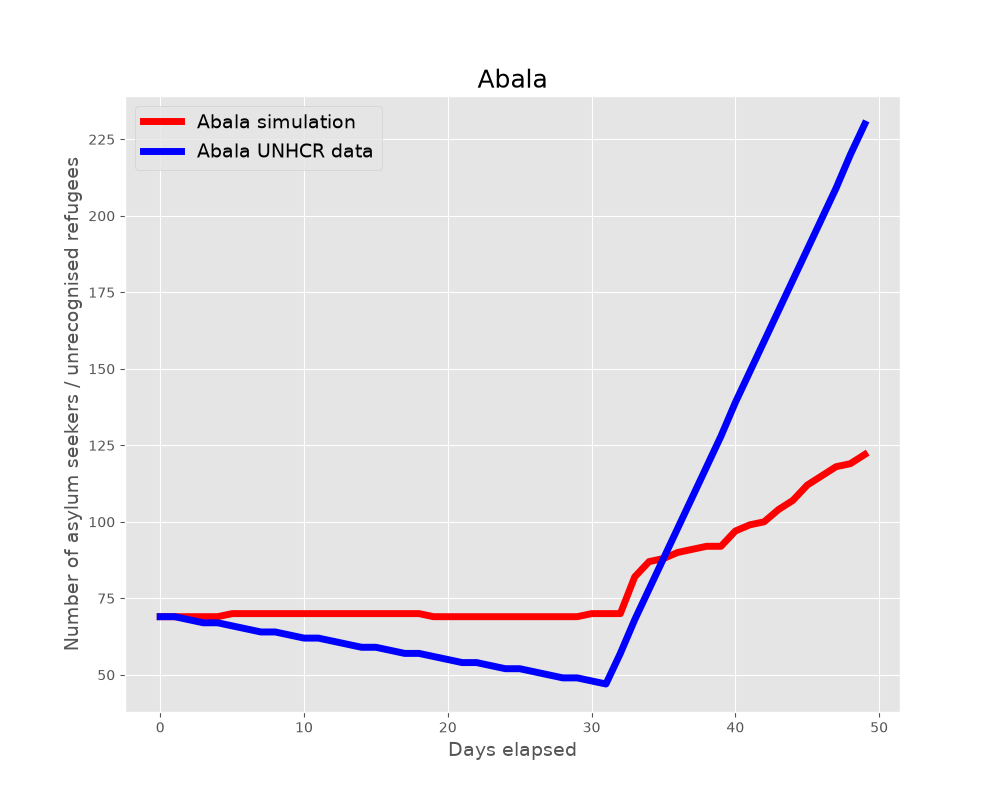

Camp comparison: Bobo-Dioulasso


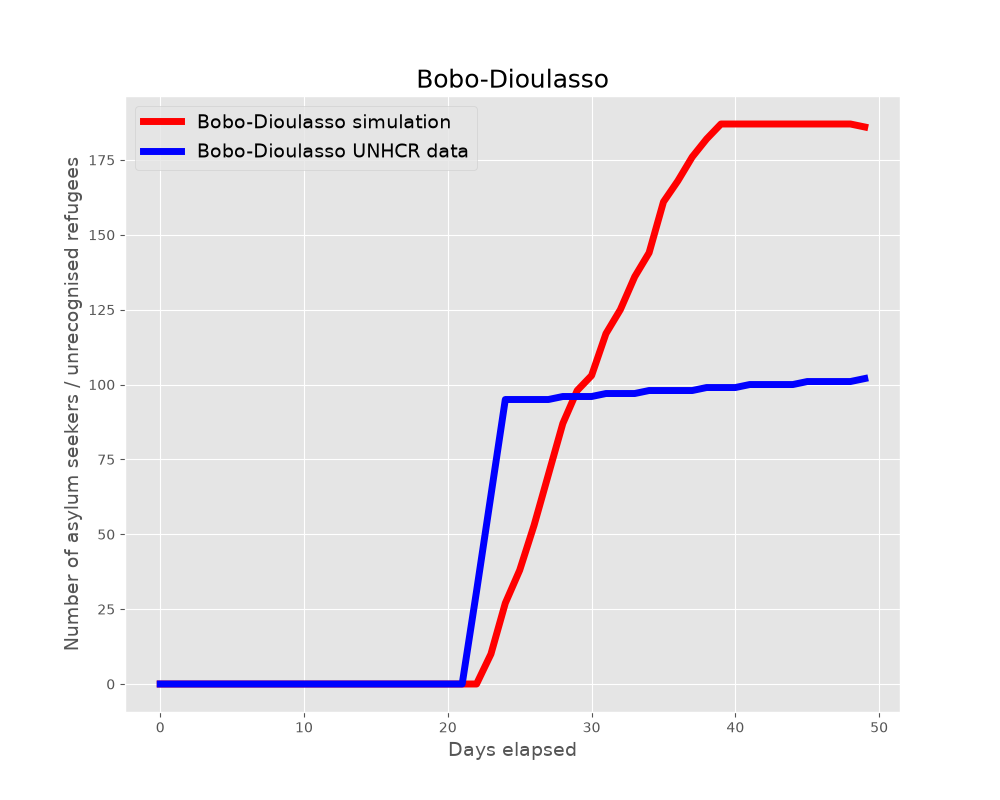

Error analysis: error_comparison.png


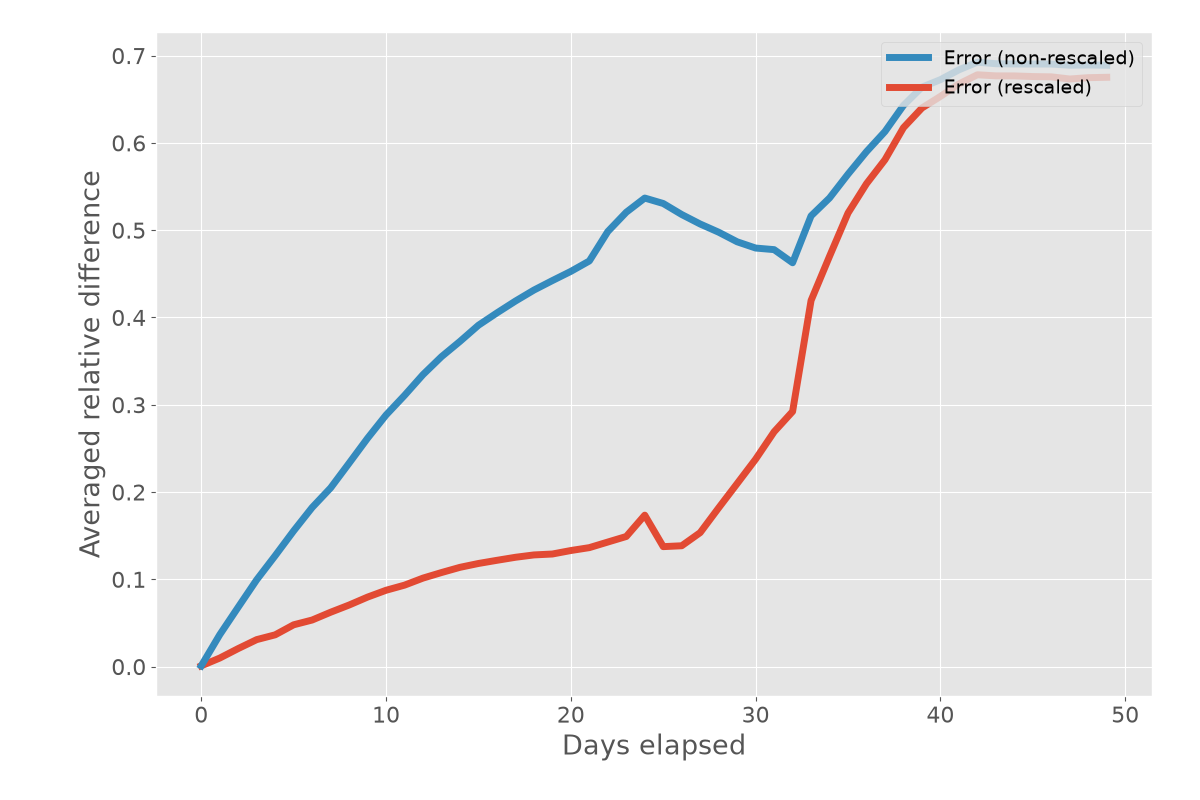

Error analysis: error.png


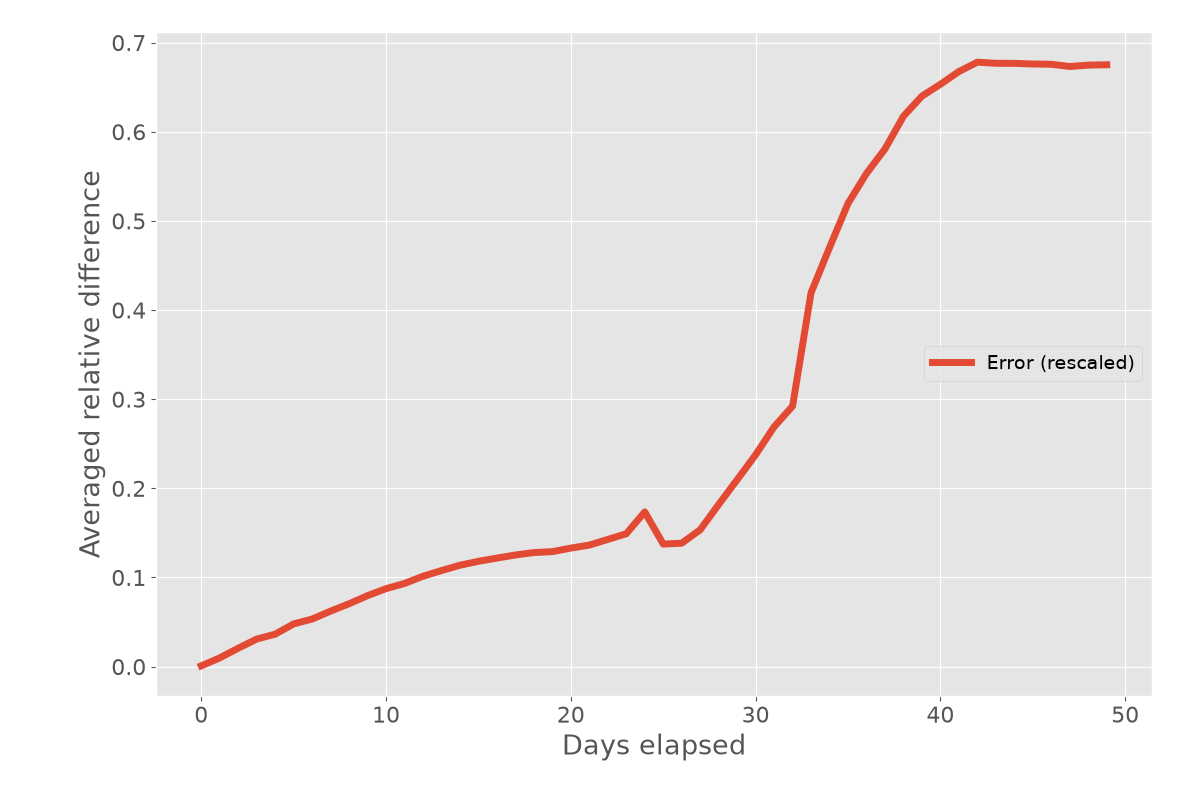

In [29]:
from pathlib import Path
from IPython.display import Image, display

fabsim_root = FABSIM_ROOT

result_directories = sorted(
    [
        path
        for path in (fabsim_root / "results").glob(
            "mali2012_localhost_*"
        )
        if "_SA_" not in path.name
    ],
    key=lambda path: path.stat().st_mtime,
    reverse=True,
)

if not result_directories:
    raise FileNotFoundError(
        "No fetched Mali result found. Run the baseline simulation first."
    )

result_directory = result_directories[0]
plot_directory = result_directory / "out"

print(f"Validation results: {result_directory.name}\n")

# Display two representative camp comparisons.
camp_plots = sorted((plot_directory / "camps").glob("*.png"))

for plot in camp_plots[:2]:
    print(f"Camp comparison: {plot.stem}")
    display(Image(filename=str(plot)))

# Display aggregate prediction-error plots.
error_plots = [
    plot_directory / "errors" / "error_comparison.png",
    plot_directory / "errors" / "error.png",
]

for plot in error_plots:
    if plot.is_file():
        print(f"Error analysis: {plot.name}")
        display(Image(filename=str(plot)))

# EasyVVUQ Introduction

[EasyVVUQ](https://easyvvuq.readthedocs.io/) is a Python library that simplifies **Uncertainty Quantification (UQ)** and **Sensitivity Analysis (SA)** for scientific simulations. It provides a user-friendly interface for defining uncertain parameters, generating samples, executing simulation campaigns, and analysing results.

### Key Capabilities

- **Parameter Definition**: Specify uncertain input parameters and their probability distributions.
- **Sampling**: Generate parameter samples using various methods (Monte Carlo, Latin Hypercube, Polynomial Chaos, etc.).
- **Campaign Management**: Organize and execute simulation ensembles systematically.
- **Sensitivity Analysis**: Calculate Sobol indices and other sensitivity measures to identify which uncertain parameters most significantly affect model outputs.
- **Uncertainty Quantification**: Compute statistical moments and probability distributions of model predictions.

### Role in SEAVEA Workflow

In this tutorial, EasyVVUQ works with FabSim3 and FabFlee to:

1. Define uncertain Flee parameters such as `max_move_speed` and `max_walk_speed`.
2. Generate parameter samples using polynomial chaos expansion.
3. Create a simulation campaign with one Flee run per sample.
4. Analyse the ensemble results to calculate how parameter uncertainty propagates to prediction error.

This integrated approach enables researchers to understand the sensitivity of forced-migration predictions to modelling assumptions without manually configuring hundreds of individual simulations.

### EasyVVUQ Components

EasyVVUQ works through a series of interconnected components that manage the uncertainty quantification workflow. Each component plays a specific role in transforming uncertain parameters into actionable insights about simulation sensitivity.

| Component | What it means | Your FLEE example |
| --- | --- | --- |
| **Parameter distributions** | Define uncertain inputs | `max_move_speed`, `max_walk_speed` |
| **Sampler** | Chooses parameter combinations | Different speed values to test |
| **Encoder** | Writes parameter values into input files | Creates FLEE input/config file |
| **Decoder** | Reads simulation output | Extracts total error / camp population |
| **Analysis** | Interprets results | Sobol sensitivity indices |

### Workflow Overview

1. **Parameter Distributions**: You specify which input parameters are uncertain and their probability distributions (e.g., `max_move_speed` ranges from 2 to 4 km/day).

2. **Sampler**: EasyVVUQ generates parameter samples using methods such as Polynomial Chaos Expansion, Monte Carlo, or Latin Hypercube Sampling. Each sample represents a unique combination of uncertain parameters.

3. **Encoder**: For each sample, the encoder converts parameter values into FLEE-compatible input files and configuration settings.

4. **Simulation Execution**: FLEE runs with each encoded parameter set, producing camp population time series and other outputs.

5. **Decoder**: After simulation, the decoder extracts relevant outputs (e.g., total prediction error, camp populations) from FLEE results.

6. **Analysis**: Statistical methods compute sensitivity indices (Sobol indices), uncertainty bounds, and other measures that quantify how parameter uncertainty propagates to model predictions.

This modular design allows EasyVVUQ to work with any simulation tool by simply changing the encoder and decoder while keeping the sampling and analysis components generic.

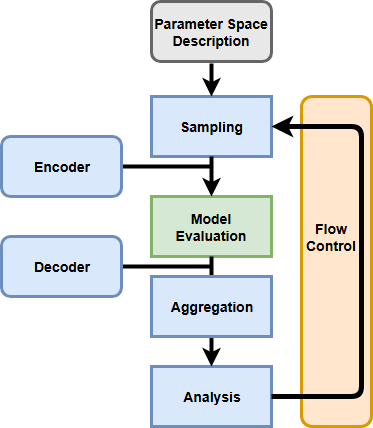


#### Install EasyVVUQ into FabSim3’s environment
The notebook launches FabSim3 using its own interpreter, so EasyVVUQ must exist there.

The EasyVVUQ 1.3 release requires NumPy < 2, which has no wheels for Python 3.13 or newer. On those Python versions the cell installs the development version of EasyVVUQ from GitHub, which supports NumPy 2. An existing EasyVVUQ 1.3 or newer is kept, and pip installs the matching Chaospy version:

In [30]:
%%bash
: "${FABSIM_ROOT:?Run the Workspace paths cell first}"

"$FABSIM_PYTHON" - <<'PYTHON'
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version

try:
    installed = version("easyvvuq")
except PackageNotFoundError:
    installed = None

if installed and tuple(int(part) for part in installed.split(".")[:2]) >= (1, 3):
    print(f"EasyVVUQ {installed} is already installed for {sys.executable}")
else:
    if sys.version_info >= (3, 13):
        # The 1.3 release needs NumPy < 2, which has no wheels for Python 3.13+
        package = "easyvvuq @ git+https://github.com/UCL-CCS/EasyVVUQ.git@dev"
    else:
        package = "easyvvuq==1.3"
    subprocess.run([sys.executable, "-m", "pip", "install", package, "chaospy"], check=True)
PYTHON

  Cloning https://github.com/UCL-CCS/EasyVVUQ.git (to revision dev) to /private/var/folders/fd/h5kr8pc51xj_hz7757c1_wsh0000gn/T/pip-install-tzteg_6w/easyvvuq_15dc49c3bbb44a989e0220c17c31913d


  Running command git clone --filter=blob:none --quiet https://github.com/UCL-CCS/EasyVVUQ.git /private/var/folders/fd/h5kr8pc51xj_hz7757c1_wsh0000gn/T/pip-install-tzteg_6w/easyvvuq_15dc49c3bbb44a989e0220c17c31913d


  Resolved https://github.com/UCL-CCS/EasyVVUQ.git to commit 3232fbac0b84ee8ba38e4cdc14b450c5981bced6
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached chaospy-4.3.21-py3-none-any.whl.metadata (5.4 kB)
  Using cached numpoly-1.3.9-cp313-cp313-macosx_15_0_arm64.whl
  Using cached sqlalchemy-2.1.6-cp313-cp313-macosx_11_0_arm64.whl.metadata (9.7 kB)
  Using cached cerberus-1.3.8-py3-none-any.whl.metadata (5.5 kB)
  Using cached dask_jobqueue-0.9.0-py2.py3-none-any.whl.metadata (1.3 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached dill-0.4.1-py3-none-any.whl.metadata (10 kB)
  Using cached tqdm-4.70.1


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: /Users/dianasuleimenova/seavea/FabSim3/VirtualEnv/bin/python -m pip install --upgrade pip


The next cells also import EasyVVUQ in this notebook's own kernel, so make sure it is installed there too:

In [31]:
import sys
from importlib.metadata import PackageNotFoundError, version

try:
    installed = version("easyvvuq")
except PackageNotFoundError:
    installed = None

if installed and tuple(int(part) for part in installed.split(".")[:2]) >= (1, 3):
    print(f"EasyVVUQ {installed} is already installed in this kernel")
elif sys.version_info >= (3, 13):
    # The 1.3 release needs NumPy < 2, which has no wheels for Python 3.13+
    %pip install "easyvvuq @ git+https://github.com/UCL-CCS/EasyVVUQ.git@dev" chaospy
else:
    %pip install easyvvuq==1.3 chaospy

EasyVVUQ 1.3.0.1 is already installed in this kernel


### Importing EasyVVUQ and Chaospy

**EasyVVUQ** is the core library for uncertainty quantification and sensitivity analysis. It provides the tools to define parameter distributions, manage sampling campaigns, and calculate sensitivity indices like Sobol indices.

**Chaospy** is a polynomial chaos expansion library that EasyVVUQ uses for advanced sampling and uncertainty propagation. It enables efficient parameter sampling and surrogate modelling through polynomial chaos methods.

Together, these libraries enable the automated generation of parameter samples and the statistical analysis of how uncertain inputs propagate through the Flee migration model.

In [32]:
import easyvvuq as uq
import chaospy as cp

### Read the Real FabFlee Uncertainty Configuration

The uncertain parameters are defined in FabFlee’s `flee_SA_config.yml` file. This is the same configuration used by the real EasyVVUQ sensitivity-analysis workflow.

The cell below reads the selected parameters and their ranges directly from that file. This ensures that the parameter values displayed in the notebook match those used to generate and execute the Flee simulation ensemble.

In [33]:
from pathlib import Path
import yaml

fabsim_root = FABSIM_ROOT
sa_config_file = (
    fabsim_root
    / "plugins"
    / "FabFlee"
    / "SA"
    / "flee_SA_config.yml"
)

with sa_config_file.open(encoding="utf-8") as stream:
    sa_config = yaml.safe_load(stream)

flee_parameters = {}

for name in sa_config["selected_vary_parameters"]:
    lower, upper = sa_config["vary_parameters_range"][name]["range"]
    flee_parameters[name] = {
        "min": lower,
        "max": upper,
        "unit": "km/day",
    }

print(f"Configuration: {sa_config_file}")

for name, spec in flee_parameters.items():
    print(
        f"{name}: Uniform({spec['min']}, {spec['max']}) "
        f"{spec['unit']}"
    )

Configuration: /Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/SA/flee_SA_config.yml
max_move_speed: Uniform(100, 500) km/day
max_walk_speed: Uniform(10, 100) km/day


##### Parameter Exploration

To perform sensitivity analysis on input parameters of Flee, we mainly focus on two sampler examples, namely (a) SCSampler (Stochastic Collocation sampler) and (b) PCESampler (Polynomial Chaos Expansion sampler), that are available in EasyVVUQ. The configuration for SA can be set in `flee_SA_config.yml` located in `FabSim3/plugin/FabFlee` directory. All required configurations for FabFlee SA, such as sampler name, varying input parameters, and the number of polynomial order, are loaded from `flee_SA_config.yml` file. To illustrate, we present an example of two `config` parameters below, namely (`max_move_speed` and `max_walk_speed`):


In [34]:
from pathlib import Path
import yaml

config_path = (
    FABSIM_ROOT
    / "plugins"
    / "FabFlee"
    / "SA"
    / "flee_SA_config.yml"
)

with config_path.open(encoding="utf-8") as file:
    flee_sa_config = yaml.safe_load(file)

summary = {
    "selected_vary_parameters":
        flee_sa_config["selected_vary_parameters"],
    "distribution_type":
        flee_sa_config["distribution_type"],
    "polynomial_order":
        flee_sa_config["polynomial_order"],
    "sampler_name":
        flee_sa_config["sampler_name"],
}

print(yaml.safe_dump(summary, sort_keys=False))

selected_vary_parameters:
- max_move_speed
- max_walk_speed
distribution_type: Uniform
polynomial_order: 2
sampler_name: SCSampler



### Create the Chaospy Distributions

EasyVVUQ uses Chaospy distributions to represent uncertain inputs. The distributions below are created from the parameter ranges read from FabFlee’s real sensitivity-analysis configuration.

These distributions will be passed to the EasyVVUQ sampler in the next step.

In [35]:
distribution_type = sa_config["distribution_type"]

if distribution_type == "Uniform":
    distribution_class = cp.Uniform
elif distribution_type == "DiscreteUniform":
    distribution_class = cp.DiscreteUniform
else:
    raise ValueError(f"Unsupported distribution: {distribution_type}")

vary = {
    name: distribution_class(spec["min"], spec["max"])
    for name, spec in flee_parameters.items()
}

vary

{'max_move_speed': Uniform(lower=100, upper=500),
 'max_walk_speed': Uniform(lower=10, upper=100)}

### Create the EasyVVUQ Sampler

The sampler chooses the parameter combinations used in the sensitivity study. Its type, polynomial order, and quadrature settings are read from FabFlee’s real configuration.

This cell previews the same sampling strategy that `flee_init_SA` will use when creating the real simulation ensemble.

In [36]:
sampler_name = sa_config["sampler_name"]

if sampler_name == "SCSampler":
    sampler = uq.sampling.SCSampler(
        vary=vary,
        polynomial_order=sa_config["polynomial_order"],
        quadrature_rule=sa_config["quadrature_rule"],
        growth=sa_config["growth"],
        sparse=sa_config["sparse"],
        midpoint_level1=sa_config["midpoint_level1"],
        dimension_adaptive=sa_config["dimension_adaptive"],
    )

elif sampler_name == "PCESampler":
    sampler = uq.sampling.PCESampler(
        vary=vary,
        polynomial_order=sa_config["polynomial_order"],
        rule=sa_config["quadrature_rule"],
        sparse=sa_config["sparse"],
        growth=sa_config["growth"],
    )

else:
    raise ValueError(f"Unsupported EasyVVUQ sampler: {sampler_name}")

print(f"Sampler: {sampler_name}")
print(f"Polynomial order: {sa_config['polynomial_order']}")
print(sampler)

Sampler: SCSampler
Polynomial order: 2


The following cell displays the parameter combinations generated by the configured sampler. These provide a preview of the samples that FabFlee will regenerate when `flee_init_SA` creates the real EasyVVUQ campaign.

In [37]:
def clean_sample(sample):
    """
    Convert EasyVVUQ/NumPy values into standard Python values
    so the generated parameter combinations are easy to display.
    """
    return {
        key: value.item() if hasattr(value, "item") else value
        for key, value in sample.items()
    }


preview_parameter_sets = [
    clean_sample(sample)
    for sample in sampler
]

print(
    f"EasyVVUQ generated {len(preview_parameter_sets)} "
    "parameter sets:\n"
)

for index, sample in enumerate(preview_parameter_sets):
    print(f"Sample {index}: {sample}")

EasyVVUQ generated 9 parameter sets:

Sample 0: {'max_move_speed': 145.08066615170333, 'max_walk_speed': 20.14314988413324}
Sample 1: {'max_move_speed': 145.08066615170333, 'max_walk_speed': 55.0}
Sample 2: {'max_move_speed': 145.08066615170333, 'max_walk_speed': 89.85685011586676}
Sample 3: {'max_move_speed': 300.00000000000006, 'max_walk_speed': 20.14314988413324}
Sample 4: {'max_move_speed': 300.00000000000006, 'max_walk_speed': 55.0}
Sample 5: {'max_move_speed': 300.00000000000006, 'max_walk_speed': 89.85685011586676}
Sample 6: {'max_move_speed': 454.9193338482967, 'max_walk_speed': 20.14314988413324}
Sample 7: {'max_move_speed': 454.9193338482967, 'max_walk_speed': 55.0}
Sample 8: {'max_move_speed': 454.9193338482967, 'max_walk_speed': 89.85685011586676}


### Generate and Execute the Real EasyVVUQ Ensemble

FabFlee’s `flee_init_SA` task creates an EasyVVUQ campaign from the configuration examined above. For each sampled parameter combination, EasyVVUQ generates a `simsetting.yml` file and FabSim3 executes a real Mali Flee simulation.

Each simulation produces an `out.csv` file containing model predictions and the total prediction error. A 30-day simulation period is used to keep the tutorial runtime manageable.

In [38]:
%%bash
set -e

export MPLBACKEND=Agg

: "${FABSIM_ROOT:?Run the Workspace paths cell first}"

if [ ! -x "$FABSIM_PYTHON" ]; then
    echo "FabSim3 Python environment not found: $FABSIM_PYTHON"
    exit 1
fi

cd "$FABSIM_ROOT"

"$FABSIM_PYTHON" -X utf8 ./fabsim/bin/fabsim \
    localhost flee_init_SA:mali2012,simulation_period=30

  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/FabFlee.py", line 1072, in <module>
    from plugins.FabFlee.vis.flee_geo import *
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/vis/flee_geo.py", line 8, in <module>
    import plotly.express as px


[loading plugin] FabFlee ...
Error: failed to import settings module flee_vis
<class 'ModuleNotFoundError'>
ModuleNotFoundError("No module named 'plotly'")
The FabFlee flee_vis functionalities are not imported as a result.
[Executing task] flee_init_SA
calling task flee_init_SA from plugin FabFlee
╭─────────────── New/Updated environment variables from FabFlee plugin ────────────────��
│ env :                                                                                │
│   --- python3_command : python3                                                      │
│   +++ python3_command : /Users/dianasuleimenova/seavea/FabSim3/VirtualEnv/bin/python │
│ env :                                                                                │
│   +++ UNHCR_uncertainty is a new added key                                           │
│ env :                                                                                │
│   +++ FLEE_TYPE_CHECK is a new added key                                   

/Users/dianasuleimenova/seavea/FabSim3/VirtualEnv/lib/python3.13/site-packages/cerberus/validator.py:618: UserWarning: These types are defined both with a method and in the'types_mapping' property of this validator: {'integer'}
  warn(
/Users/dianasuleimenova/seavea/FabSim3/VirtualEnv/lib/python3.13/site-packages/cerberus/validator.py:618: UserWarning: These types are defined both with a method and in the'types_mapping' property of this validator: {'integer'}
  warn(


building file list ... 
[sender] showing file campaign.db because of pattern *.db
[sender] hiding directory flee_SA_SCSampler_mali2012vbihiepz because of pattern *
[sender] hiding directory backup because of pattern *
done
delta-transmission disabled for local transfer or --whole-file
campaign.db
total: matches=0  hash_hits=0  false_alarms=0 data=36864

sent 37,023 bytes  received 105 bytes  74,256.00 bytes/sec
total size is 36,864  speedup is 0.99
building file list ... done
SWEEP/
SWEEP/run_1/
SWEEP/run_1/simsetting.yml
SWEEP/run_2/
SWEEP/run_2/simsetting.yml
SWEEP/run_3/
SWEEP/run_3/simsetting.yml
SWEEP/run_4/
SWEEP/run_4/simsetting.yml
SWEEP/run_5/
SWEEP/run_5/simsetting.yml
SWEEP/run_6/
SWEEP/run_6/simsetting.yml
SWEEP/run_7/
SWEEP/run_7/simsetting.yml
SWEEP/run_8/
SWEEP/run_8/simsetting.yml
SWEEP/run_9/
SWEEP/run_9/simsetting.yml

sent 1.66K bytes  received 340 bytes  4.01K bytes/sec
total size is 155.47K  speedup is 77.58
{'range': [100, 500]}
{'range': [10, 100]}
[local] rsync 

YAML file: simsetting.yml
YAML: {'move_rules': {'max_move_speed': 145.08066615170333, 'max_walk_speed': 55.0, 'max_crossing_speed': 20, 'foreign_weight': 1.0, 'camp_weight': 1.0, 'conflict_weight': 0.25, 'conflict_movechance': 1.0, 'camp_movechance': 0.001, 'default_movechance': 0.3, 'idpcamp_movechance': 0.1}}
Take from population? false
Spawn decay set to: None, with interval 30
INFO: Fixed Route Generation for Locations: False
Move rules set to: {'FloodRulesEnabled': False, 'FloodForecaster': False, 'flood_forecaster_timescale': 0, 'MaxMoveSpeed': 145.08066615170333, 'MaxWalkSpeed': 55.0, 'MaxCrossingSpeed': 20.0, 'ForeignWeight': 1.0, 'CampWeight': 1.0, 'ConflictWeight': 0.25, 'ConflictMoveChance': 1.0, 'CampMoveChance': 0.001, 'IDPCampMoveChance': 0.1, 'DefaultMoveChance': 0.3, 'AwarenessLevel': 1, 'CapacityBuffer': 0.9, 'CapacityScaling': 1.0, 'AvoidShortStints': False, 'StartOnFoot': False, 'DistanceSoftening': 10.0, 'WeightSoftening': 0.0, 'WeightPower': 1.0, 'DistancePower': 1

...

Transfer starting: 39 files
acled.csv
run_UNHCR_uncertainty.py
simsetting.yml
example_sweepdir/
example_sweepdir/100/
example_sweepdir/100/simsetting.csv
example_sweepdir/200/
example_sweepdir/200/simsetting.csv
example_sweepdir/400/
example_sweepdir/400/simsetting.csv
input_csv/
input_csv/closures.csv
input_csv/conflicts.csv
input_csv/demographics_age.csv
input_csv/demographics_ethnicity.csv
input_csv/demographics_gender.csv
input_csv/locations.csv
input_csv/registration_corrections.csv
input_csv/routes.csv
input_csv/sim_period.csv
source_data/
source_data/bf-bobo.csv
source_data/bf-goudoubo.csv
source_data/bf-mentao.csv
source_data/bf-ouagadougou.csv
source_data/camp_issues.md
source_data/data_layout.csv
source_data/mau-fassala-mbera.csv
source_data/mau-fassala.csv
source_data/mau-mbera.csv
source_data/nig-abala.csv
source_data/nig-intikane.csv
source_data/nig-mangaize.csv
source_data/nig-niamey.csv
source_data/nig-tabareybarey.csv
source_data/refugees.csv
source_data/religion.csv
so

YAML file: simsetting.yml
YAML: {'move_rules': {'max_move_speed': 454.9193338482967, 'max_walk_speed': 89.85685011586676, 'max_crossing_speed': 20, 'foreign_weight': 1.0, 'camp_weight': 1.0, 'conflict_weight': 0.25, 'conflict_movechance': 1.0, 'camp_movechance': 0.001, 'default_movechance': 0.3, 'idpcamp_movechance': 0.1}}
Take from population? false
Spawn decay set to: None, with interval 30
INFO: Fixed Route Generation for Locations: False
Move rules set to: {'FloodRulesEnabled': False, 'FloodForecaster': False, 'flood_forecaster_timescale': 0, 'MaxMoveSpeed': 454.9193338482967, 'MaxWalkSpeed': 89.85685011586676, 'MaxCrossingSpeed': 20.0, 'ForeignWeight': 1.0, 'CampWeight': 1.0, 'ConflictWeight': 0.25, 'ConflictMoveChance': 1.0, 'CampMoveChance': 0.001, 'IDPCampMoveChance': 0.1, 'DefaultMoveChance': 0.3, 'AwarenessLevel': 1, 'CapacityBuffer': 0.9, 'CapacityScaling': 1.0, 'AvoidShortStints': False, 'StartOnFoot': False, 'DistanceSoftening': 10.0, 'WeightSoftening': 0.0, 'WeightPower':

Transfer starting: 39 files
acled.csv
run_UNHCR_uncertainty.py
simsetting.yml
example_sweepdir/
example_sweepdir/100/
example_sweepdir/100/simsetting.csv
example_sweepdir/200/
example_sweepdir/200/simsetting.csv
example_sweepdir/400/
example_sweepdir/400/simsetting.csv
input_csv/
input_csv/closures.csv
input_csv/conflicts.csv
input_csv/demographics_age.csv
input_csv/demographics_ethnicity.csv
input_csv/demographics_gender.csv
input_csv/locations.csv
input_csv/registration_corrections.csv
input_csv/routes.csv
input_csv/sim_period.csv
source_data/
source_data/bf-bobo.csv
source_data/bf-goudoubo.csv
source_data/bf-mentao.csv
source_data/bf-ouagadougou.csv
source_data/camp_issues.md
source_data/data_layout.csv
source_data/mau-fassala-mbera.csv
source_data/mau-fassala.csv
source_data/mau-mbera.csv
source_data/nig-abala.csv
source_data/nig-intikane.csv
source_data/nig-mangaize.csv
source_data/nig-niamey.csv
source_data/nig-tabareybarey.csv
source_data/refugees.csv
source_data/religion.csv
so

YAML file: simsetting.yml
YAML: {'move_rules': {'max_move_speed': 454.9193338482967, 'max_walk_speed': 20.14314988413324, 'max_crossing_speed': 20, 'foreign_weight': 1.0, 'camp_weight': 1.0, 'conflict_weight': 0.25, 'conflict_movechance': 1.0, 'camp_movechance': 0.001, 'default_movechance': 0.3, 'idpcamp_movechance': 0.1}}
Take from population? false
Spawn decay set to: None, with interval 30
INFO: Fixed Route Generation for Locations: False
Move rules set to: {'FloodRulesEnabled': False, 'FloodForecaster': False, 'flood_forecaster_timescale': 0, 'MaxMoveSpeed': 454.9193338482967, 'MaxWalkSpeed': 20.14314988413324, 'MaxCrossingSpeed': 20.0, 'ForeignWeight': 1.0, 'CampWeight': 1.0, 'ConflictWeight': 0.25, 'ConflictMoveChance': 1.0, 'CampMoveChance': 0.001, 'IDPCampMoveChance': 0.1, 'DefaultMoveChance': 0.3, 'AwarenessLevel': 1, 'CapacityBuffer': 0.9, 'CapacityScaling': 1.0, 'AvoidShortStints': False, 'StartOnFoot': False, 'DistanceSoftening': 10.0, 'WeightSoftening': 0.0, 'WeightPower':

[local] ssh -Y -p 22 dianasuleimenova@localhost 'cd /Users/dianasuleimenova/seavea/FabSim3/localhost_exe/FabSim/results/mali2012_localhost_1_SA_SCSampler/RUNS/run_2 && true &&  /Users/dianasuleimenova/seavea/FabSim3/localhost_exe/FabSim/results/mali2012_localhost_1_SA_SCSampler/RUNS/run_2/mali2012_localhost_1_SA_SCSampler_run_2.sh'
Use fabsim localhost fetch_results to copy the results back to local machine!
[local] ssh -Y -p 22 dianasuleimenova@localhost 'cd /Users/dianasuleimenova/seavea/FabSim3/localhost_exe/FabSim/results/mali2012_localhost_1_SA_SCSampler/RUNS/run_5 && true &&  /Users/dianasuleimenova/seavea/FabSim3/localhost_exe/FabSim/results/mali2012_localhost_1_SA_SCSampler/RUNS/run_5/mali2012_localhost_1_SA_SCSampler_run_5.sh'
Use fabsim localhost fetch_results to copy the results back to local machine!
[local] ssh -Y -p 22 dianasuleimenova@localhost 'cd /Users/dianasuleimenova/seavea/FabSim3/localhost_exe/FabSim/results/mali2012_localhost_1_SA_SCSampler/RUNS/run_4 && true && 

### Inspect the Encoded Flee Configurations

EasyVVUQ’s `GenericEncoder` creates one `simsetting.yml` file for each sampled parameter combination. FabFlee places these configurations in the Mali `SWEEP` directory before FabSim3 executes the ensemble.

The following cell reads the generated files and displays the movement parameters used by each Flee run. This confirms that the EasyVVUQ samples were passed into the real model.

In [39]:
from pathlib import Path
import yaml

sweep_dir = (
    fabsim_root
    / "plugins"
    / "FabFlee"
    / "config_files"
    / "mali2012"
    / "SWEEP"
)

simsetting_files = sorted(sweep_dir.glob("run_*/simsetting.yml"))

if not simsetting_files:
    raise FileNotFoundError(
        "No encoded simsetting.yml files were found. "
        "Run Step 11 first."
    )

print(f"Found {len(simsetting_files)} encoded configurations:\n")

selected_parameters = sa_config["selected_vary_parameters"]

for simsetting_file in simsetting_files:
    with simsetting_file.open(encoding="utf-8") as stream:
        settings = yaml.safe_load(stream)

    move_rules = settings["move_rules"]
    sampled_values = {
        parameter: move_rules[parameter]
        for parameter in selected_parameters
    }

    print(f"{simsetting_file.parent.name}: {sampled_values}")

Found 9 encoded configurations:

run_1: {'max_move_speed': 145.08066615170333, 'max_walk_speed': 20.14314988413324}
run_2: {'max_move_speed': 145.08066615170333, 'max_walk_speed': 55.0}
run_3: {'max_move_speed': 145.08066615170333, 'max_walk_speed': 89.85685011586676}
run_4: {'max_move_speed': 300.00000000000006, 'max_walk_speed': 20.14314988413324}
run_5: {'max_move_speed': 300.00000000000006, 'max_walk_speed': 55.0}
run_6: {'max_move_speed': 300.00000000000006, 'max_walk_speed': 89.85685011586676}
run_7: {'max_move_speed': 454.9193338482967, 'max_walk_speed': 20.14314988413324}
run_8: {'max_move_speed': 454.9193338482967, 'max_walk_speed': 55.0}
run_9: {'max_move_speed': 454.9193338482967, 'max_walk_speed': 89.85685011586676}


### Decode and Analyse the Real Ensemble Results

FabFlee’s `flee_analyse_SA` task performs the final EasyVVUQ stages. It fetches the `out.csv` file from every Flee run, uses EasyVVUQ’s `SimpleCSV` decoder to extract the `Total error` quantity of interest, and collates the results.

EasyVVUQ then calculates statistical measures and Sobol sensitivity indices. These indices show how strongly each uncertain movement parameter contributes to variation in Flee’s prediction error.

In [40]:
%%bash
set -e

export MPLBACKEND=Agg

: "${FABSIM_ROOT:?Run the Workspace paths cell first}"

if [ ! -x "$FABSIM_PYTHON" ]; then
    echo "FabSim3 Python environment not found: $FABSIM_PYTHON"
    exit 1
fi

cd "$FABSIM_ROOT"

"$FABSIM_PYTHON" -X utf8 ./fabsim/bin/fabsim \
    localhost flee_analyse_SA:mali2012

  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/FabFlee.py", line 1072, in <module>
    from plugins.FabFlee.vis.flee_geo import *
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/vis/flee_geo.py", line 8, in <module>
    import plotly.express as px


[loading plugin] FabFlee ...
Error: failed to import settings module flee_vis
<class 'ModuleNotFoundError'>
ModuleNotFoundError("No module named 'plotly'")
The FabFlee flee_vis functionalities are not imported as a result.
[Executing task] flee_analyse_SA
calling task flee_analyse_SA from plugin FabFlee
╭─────────────── New/Updated environment variables from FabFlee plugin ──────────────��─╮
│ env :                                                                                │
│   --- python3_command : python3                                                      │
│   +++ python3_command : /Users/dianasuleimenova/seavea/FabSim3/VirtualEnv/bin/python │
│ env :                                                                                │
│   +++ UNHCR_uncertainty is a new added key                                           │
│ env :                                                                                │
│   +++ FLEE_TYPE_CHECK is a new added key                             

/Users/dianasuleimenova/seavea/FabSim3/VirtualEnv/lib/python3.13/site-packages/cerberus/validator.py:618: UserWarning: These types are defined both with a method and in the'types_mapping' property of this validator: {'integer'}
  warn(


receiving file list ... done
mali2012_localhost_1_SA_SCSampler/
mali2012_localhost_1_SA_SCSampler/RUNS/
mali2012_localhost_1_SA_SCSampler/RUNS/run_1/
mali2012_localhost_1_SA_SCSampler/RUNS/run_1/out.csv
mali2012_localhost_1_SA_SCSampler/RUNS/run_2/
mali2012_localhost_1_SA_SCSampler/RUNS/run_2/out.csv
mali2012_localhost_1_SA_SCSampler/RUNS/run_3/
mali2012_localhost_1_SA_SCSampler/RUNS/run_3/out.csv
mali2012_localhost_1_SA_SCSampler/RUNS/run_4/
mali2012_localhost_1_SA_SCSampler/RUNS/run_4/out.csv
mali2012_localhost_1_SA_SCSampler/RUNS/run_5/
mali2012_localhost_1_SA_SCSampler/RUNS/run_5/out.csv
mali2012_localhost_1_SA_SCSampler/RUNS/run_6/
mali2012_localhost_1_SA_SCSampler/RUNS/run_6/out.csv
mali2012_localhost_1_SA_SCSampler/RUNS/run_7/
mali2012_localhost_1_SA_SCSampler/RUNS/run_7/out.csv
mali2012_localhost_1_SA_SCSampler/RUNS/run_8/
mali2012_localhost_1_SA_SCSampler/RUNS/run_8/out.csv
mali2012_localhost_1_SA_SCSampler/RUNS/run_9/
mali2012_localhost_1_SA_SCSampler/RUNS/run_9/out.csv

sent

### Display and Interpret the Sensitivity Results

The analysis produces first-order Sobol indices for each uncertain parameter. A larger index means that the parameter explains a greater proportion of the variation in Flee’s total prediction error.

The cell below reads the generated `sobols.yml` file, displays the mean sensitivity index for each parameter, and shows the plots created by FabFlee.

Campaign: flee_SA_SCSampler_mali2012
Number of runs: 9
Quantity of interest: Total error

Mean first-order Sobol indices:
  max_move_speed: 0.7808
  max_walk_speed: 0.0780

Generated analysis plots:
plot_sobols_first[Total error].png


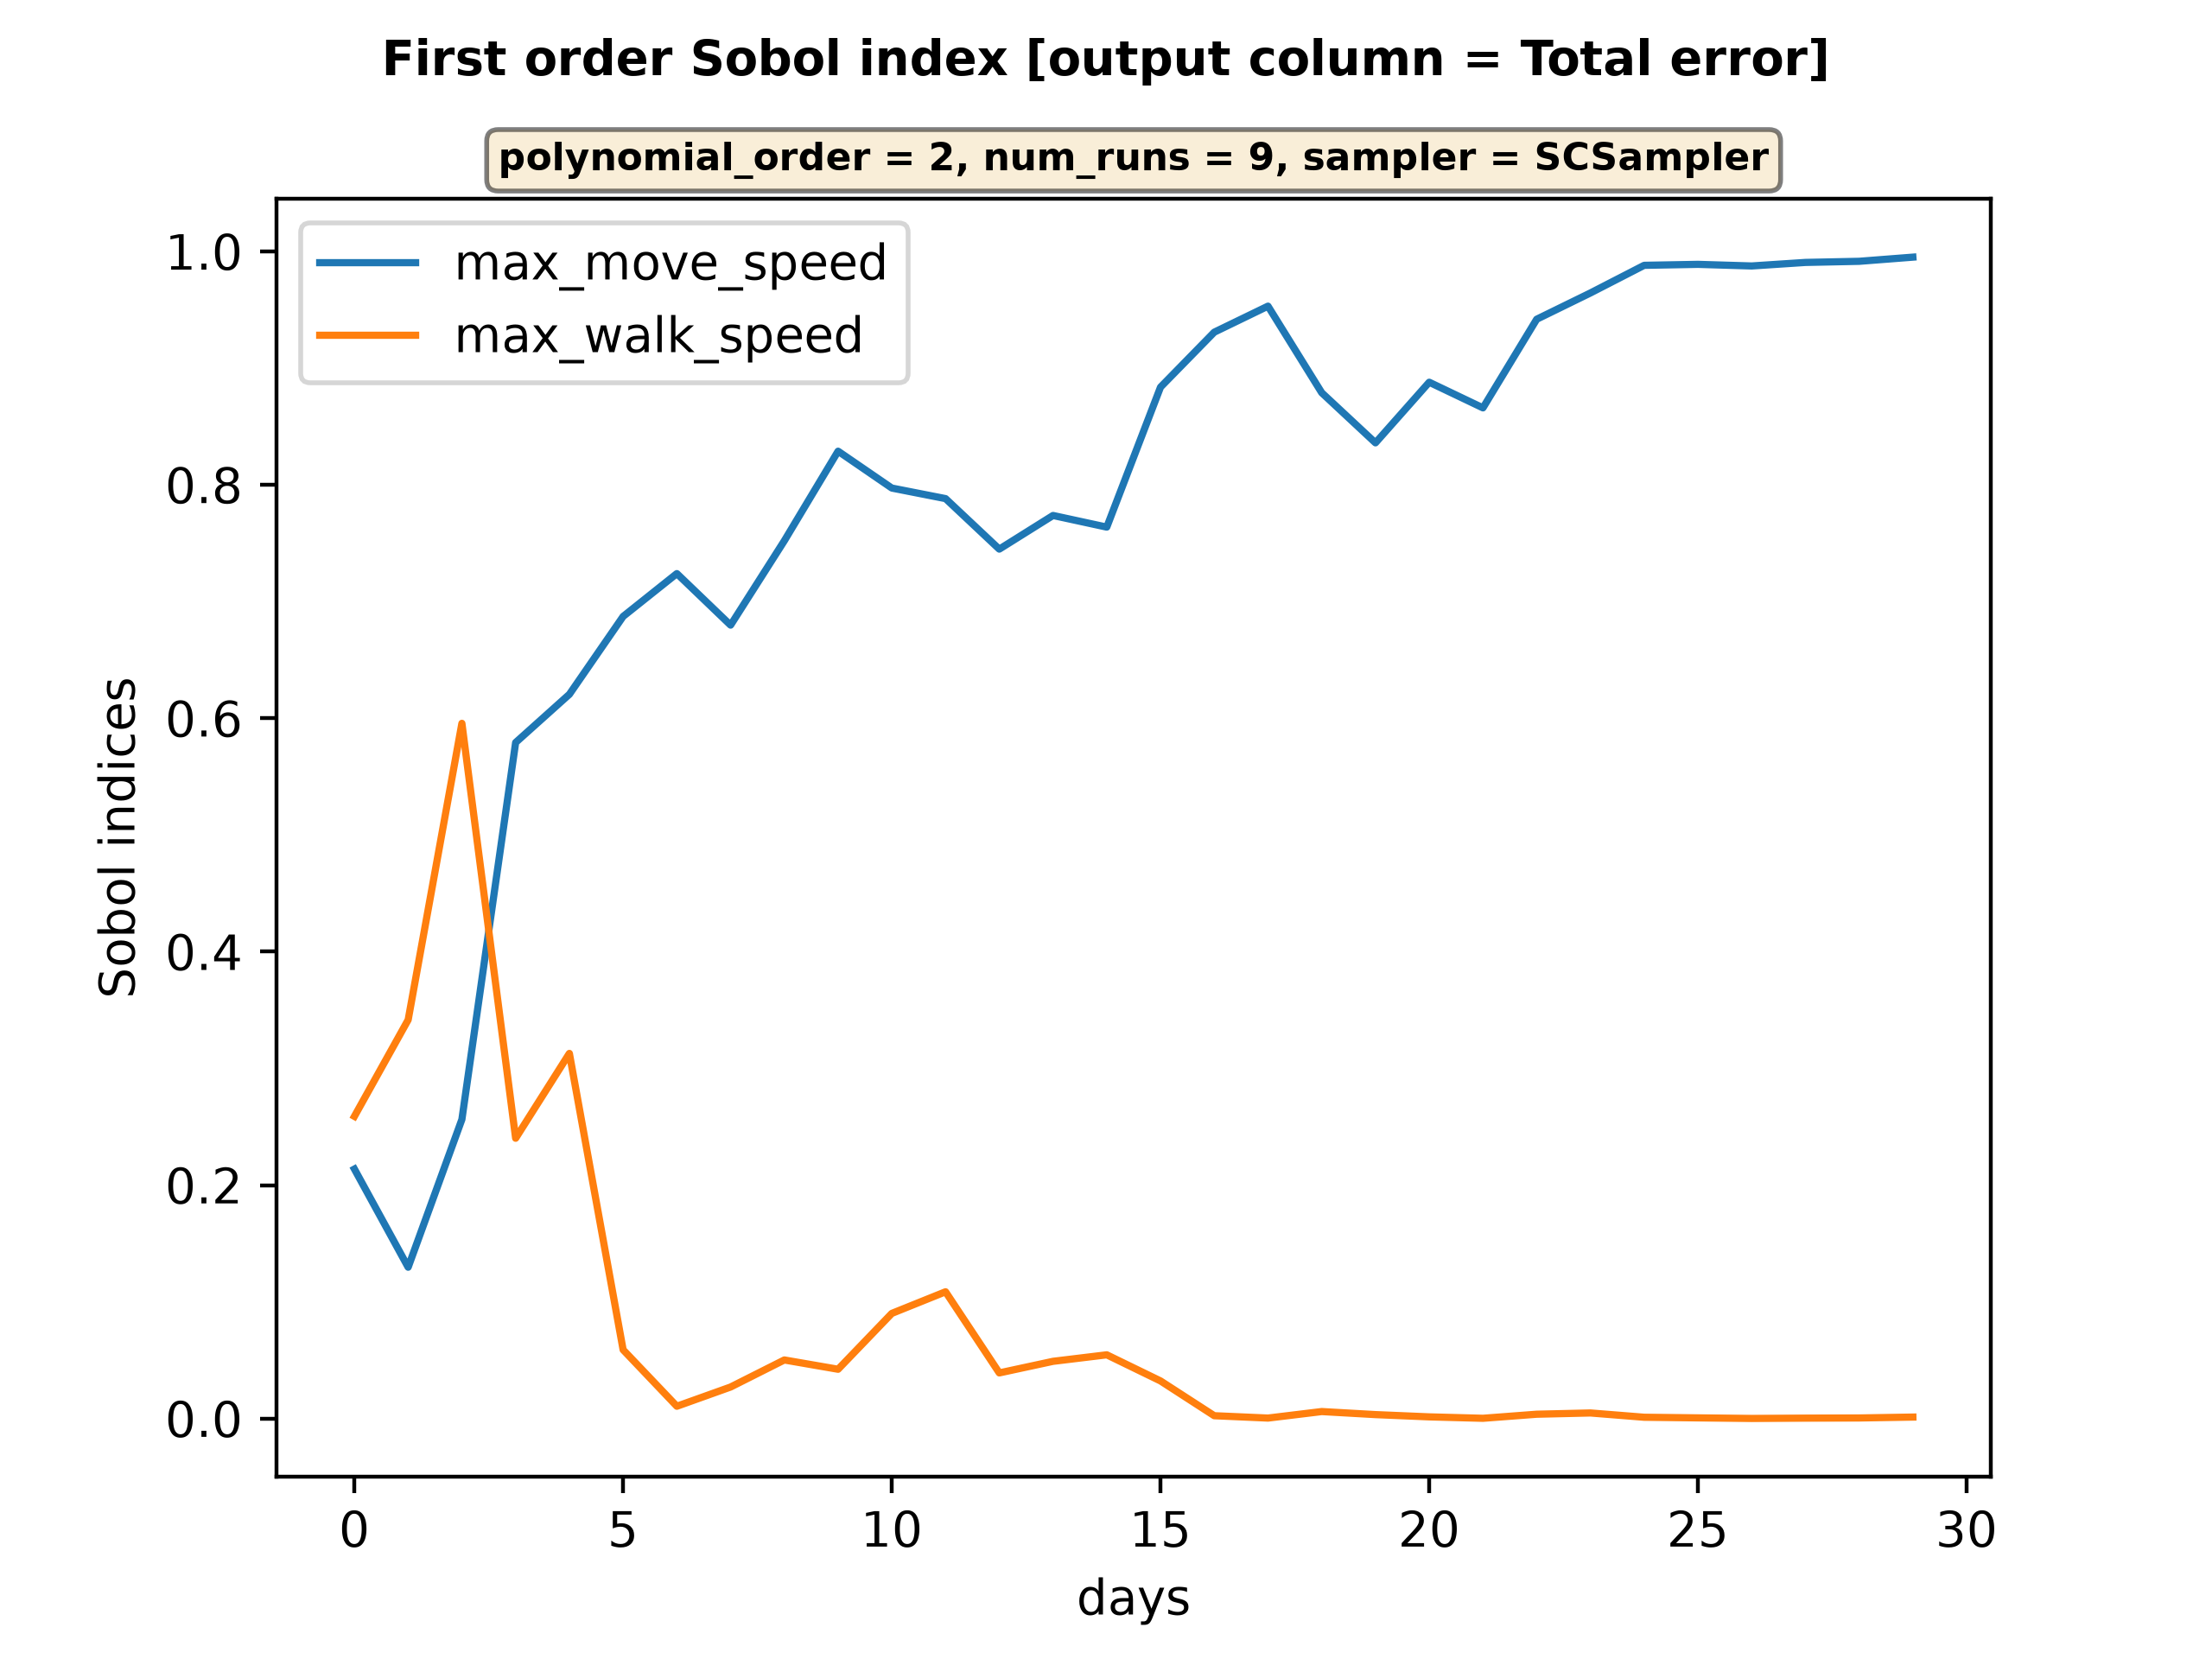

plot_statistical_moments[Total error].png


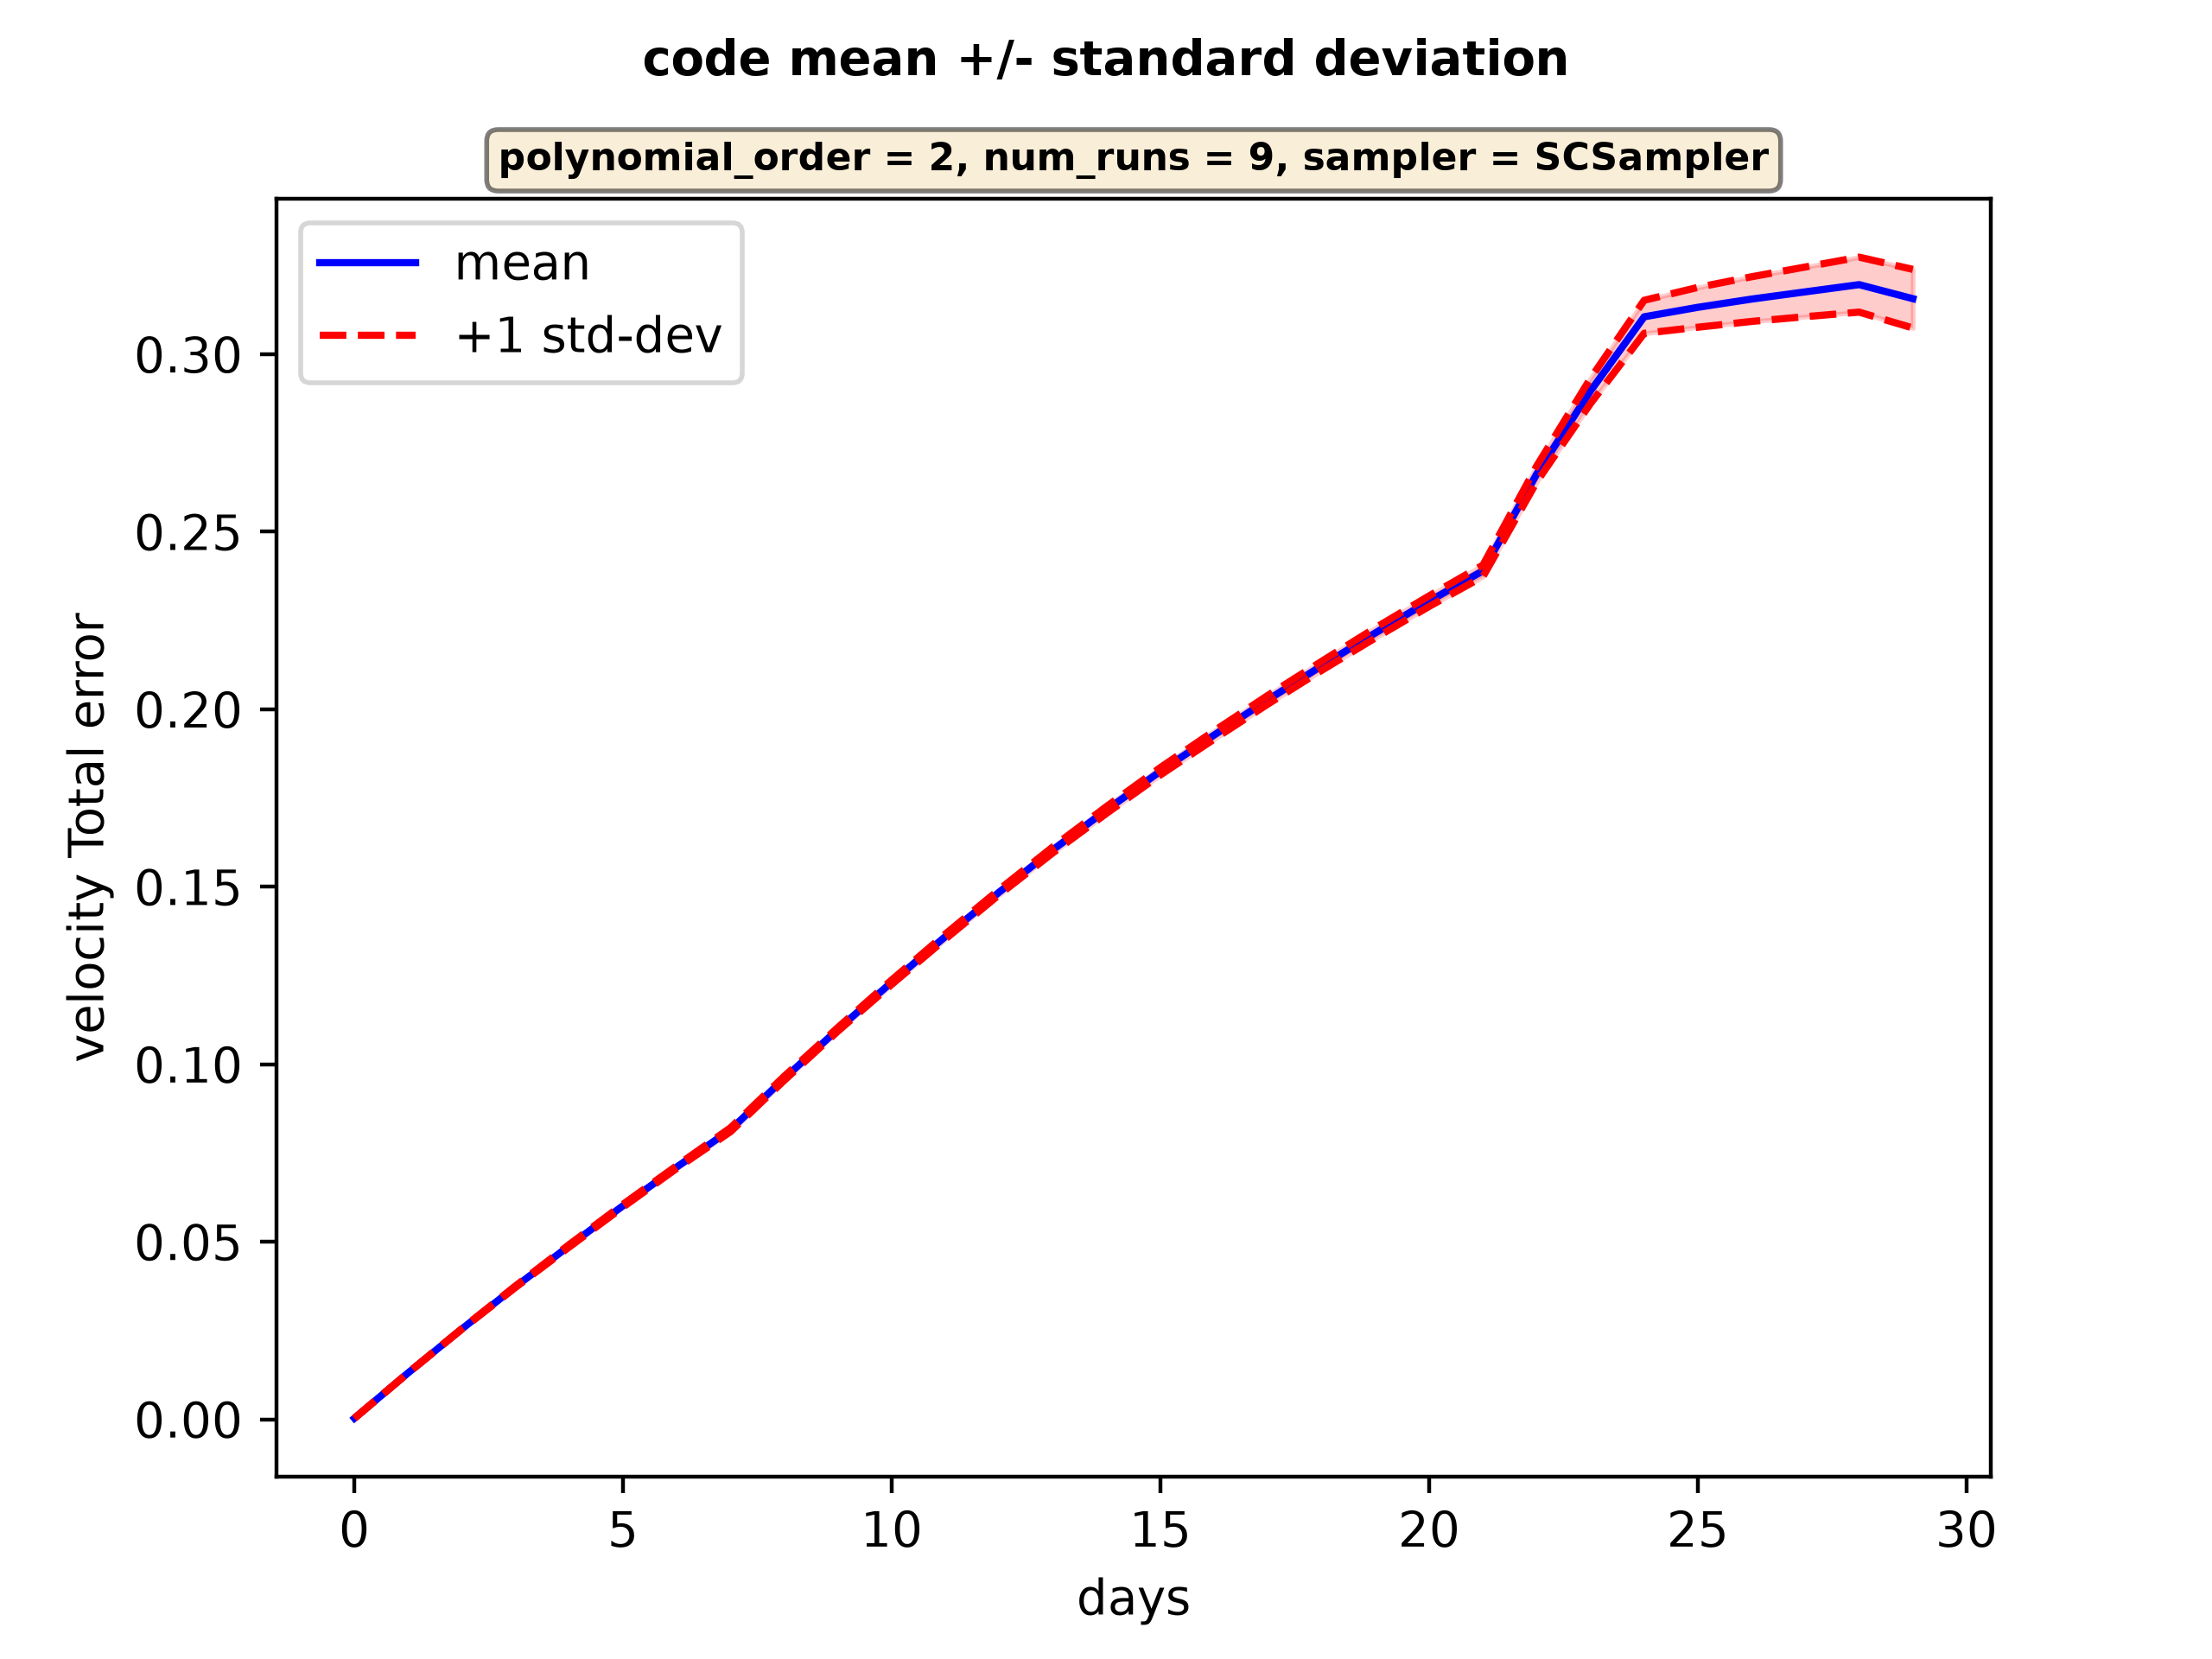

raw[Total error].png


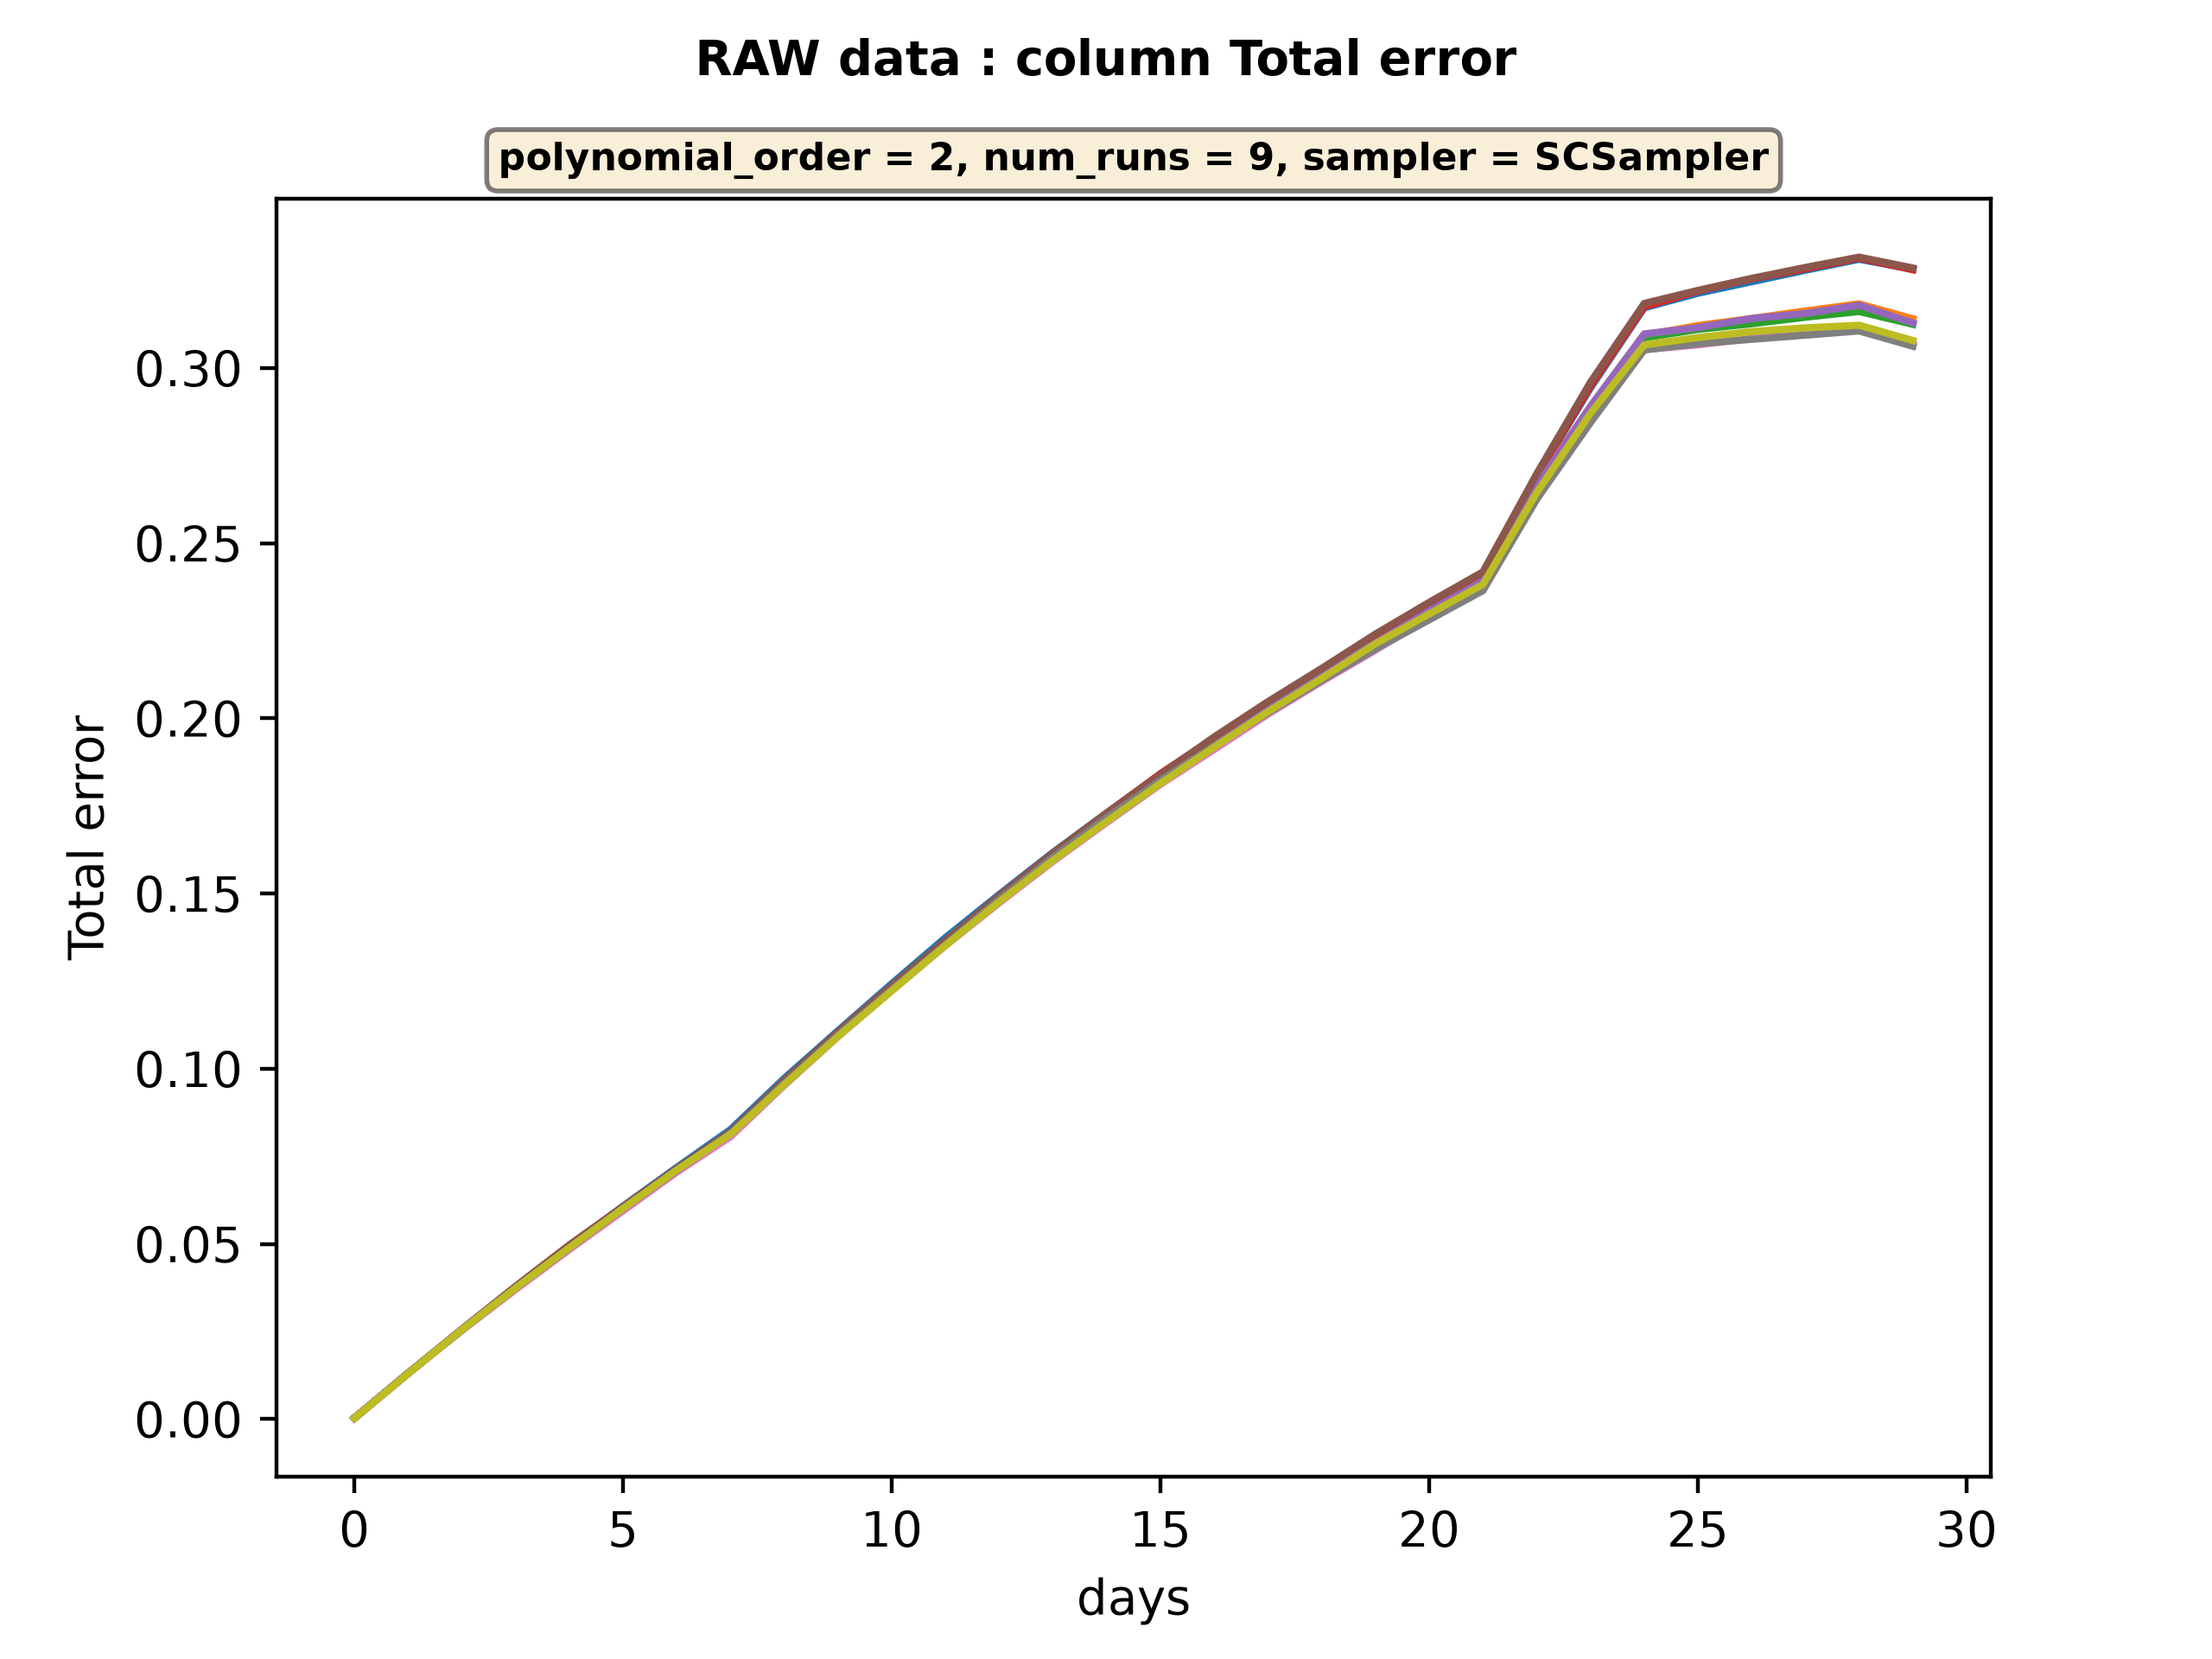

In [41]:
from IPython.display import Image, display
import yaml

campaign_dir = (
    fabsim_root
    / "plugins"
    / "FabFlee"
    / "SA"
    / f"flee_SA_{sa_config['sampler_name']}_mali2012"
)

sobols_file = campaign_dir / "sobols.yml"

if not sobols_file.is_file():
    raise FileNotFoundError(
        "Sobol results were not found. Run Step 13 first."
    )

with sobols_file.open(encoding="utf-8") as stream:
    sobol_results = yaml.safe_load(stream)

campaign_info = sobol_results["campaign_info"]

print("Campaign:", campaign_info["name"])
print("Number of runs:", campaign_info["num_runs"])
print("Quantity of interest:", campaign_info["output_column"])
print("\nMean first-order Sobol indices:")

for parameter in sa_config["selected_vary_parameters"]:
    mean_index = sobol_results[parameter]["sobols_first_mean"]
    print(f"  {parameter}: {mean_index:.4f}")

print("\nGenerated analysis plots:")

for plot_file in sorted(campaign_dir.glob("*.png")):
    print(plot_file.name)
    display(Image(filename=str(plot_file)))

# QCG-PilotJob: Running Flee Ensembles on Cirrus

The EasyVVUQ sensitivity study above creates many independent Flee simulations. That is ideal for parallel execution: each sample can run as a separate task, and the final analysis only needs the completed output files.

On a laptop, launching a small number of samples is fine. On an HPC system such as Cirrus, a realistic study may require hundreds or thousands of runs. Submitting each run as a separate scheduler job is inefficient and creates avoidable queue overhead. QCG-PilotJob solves this by submitting one pilot allocation to the scheduler and then scheduling many smaller Flee tasks inside that allocation.

In this section FabSim3 submits the Mali ensemble from the EasyVVUQ section to Cirrus with `pj_type=qcg`. One Slurm job starts QCG-PilotJob, which runs the Flee simulations side by side inside that allocation, and FabSim3 then fetches the results so they can be compared here.

## What QCG-PilotJob Adds

QCG-PilotJob is a pilot-job layer. Instead of asking the HPC scheduler for one allocation per Flee run, it asks for one allocation and then manages many subordinate tasks within it.

For this tutorial workflow:

1. EasyVVUQ defines the uncertain Flee parameters and creates the sample set.
2. FabFlee generates one Flee configuration per sample.
3. FabSim3 stages the campaign to the target machine.
4. QCG-PilotJob schedules the sample runs inside the HPC allocation.
5. FabSim3 fetches results back, and the EasyVVUQ analysis step computes the Sobol indices and plots shown earlier.

This is the same scientific workflow as the local section above; QCG-PilotJob changes where and how the independent model evaluations are executed.

## HPC Prerequisites

This section runs on **Cirrus**, EPCC's national HPC service: an HPE Cray EX4000 with 288 cores and 768 GB of memory per standard compute node, managed by the Slurm scheduler. The full beginner's guide is [Getting started with Cirrus](https://github.com/djgroen/FabSim3/blob/add-cirrus-machine-config/docs/cirrus_getting_started.md); the steps below follow it.

Before running this section, make sure you have:

- a Cirrus account in project **`tc078`**; usernames have the project code in front, for example `tc078user5`, and all jobs are charged to the `tc078` budget;
- an SSH key registered with your Cirrus account, and an authenticator app set up for the one-time code (TOTP) that Cirrus asks for at login;
- FabSim3 with the `cirrus` machine definition in `fabsim/deploy/machines.yml` (currently on the `add-cirrus-machine-config` branch of FabSim3);
- the Mali ensemble runs (the `SWEEP` folder of `mali2012`) created by `flee_init_SA` in the [EasyVVUQ section](#generate-and-execute-the-real-easyvvuq-ensemble).

Three Cirrus rules that catch people out:

1. **You are charged per core-hour.** A job that asks for 8 cores for one hour costs 8 core-hours; a whole node costs 288. Request only what you need and always set a short `--time`.
2. **Jobs must write to `/epccfs`.** Your working directory is `/epccfs/tc078/tc078/<username>`. `/home` is mounted on the login nodes only, so a job cannot read or write it, and `/work` is read-only.
3. **Nothing heavy on the login node.** Real work goes to compute nodes through Slurm.

The cells that contact Cirrus reuse a background SSH connection that you open once from a terminal (see [Log in Once](#log-in-once-multiplexing)). They stop with a message if that connection is not running.

## Configure Cirrus

### Set up SSH Access to Cirrus

Cirrus accepts an SSH key **plus** a one-time code. Without extra configuration, every `ssh`, `scp`, `rsync` and FabSim3 command would ask for a new code. To avoid this, add a `cirrus` alias with *multiplexing* to `~/.ssh/config`, replacing `<your-username>` with your Cirrus username (for example `tc078user5`):

```sh
Host cirrus
   User <your-username>
   HostName login.cirrus.ac.uk
   ServerAliveInterval 60
   ControlPath ~/.ssh/control-%r@%h:%p
   ControlMaster auto
   ControlPersist 12h
```

The last three lines keep **one** authenticated connection open in the background for 12 hours and reuse it for every later command.

If your key does not have a default name (`id_ed25519`, `id_rsa`), also add:

```sh
   IdentityFile ~/.ssh/<your-key-name>
   IdentitiesOnly yes
```

Check that the alias is in place:

In [42]:
%%bash

if grep -qE '^Host[[:space:]]+cirrus([[:space:]]|$)' ~/.ssh/config 2>/dev/null; then
    sed -n '/^Host[[:space:]]\{1,\}cirrus/,/^Host /p' ~/.ssh/config
else
    echo "No 'Host cirrus' block found in ~/.ssh/config. Add the block above first."
fi

Host cirrus
   User tc078user1
   HostName login.cirrus.ac.uk
   ServerAliveInterval 60
   ControlPath ~/.ssh/control-%r@%h:%p
   ControlMaster auto
   ControlPersist 12h
   IdentityFile ~/.ssh/id_rsa
   IdentitiesOnly yes


### Log in Once (Multiplexing)

The notebook cannot answer the one-time-code prompt, so open the background connection **from a terminal** (in VS Code: *Terminal → New Terminal*):

```sh
ssh cirrus
```

1. Enter the passphrase of your SSH key, if it has one.
2. Enter the 6-digit code from your authenticator app.
3. Once you see a prompt such as `tc078user5@login03:~$`, type `exit`. The background connection stays open.

Now check from the notebook that the connection is running. Expected output: `Master running (pid=...)`.

In [43]:
%%bash

ssh -O check cirrus || echo "No background connection. Run 'ssh cirrus' in a terminal, then re-run this cell."

Master running (pid=23946)


If you see *"Master connection does not exist"* at any point later (for example after 12 hours), run `ssh cirrus` in the terminal again.

### Set the Cirrus Variables

Your Cirrus username is read from the `User` line of the `cirrus` alias in `~/.ssh/config`, so there is nothing to type here. The project is `tc078`. `CIRRUS_MACHINE` must match the machine name known to FabSim3, and `CIRRUS_SSH` is the alias from `~/.ssh/config`. The notebook uses `mali2012` because that is the scenario used in the local sections above.

In [44]:
from pathlib import Path
import getpass
import os
import shlex
import subprocess

CIRRUS_MACHINE = "cirrus"          # FabSim3 machine name
CIRRUS_SSH = "cirrus"              # SSH alias from ~/.ssh/config
CIRRUS_PROJECT = "tc078"           # project and budget code

# Read the username from ~/.ssh/config; `ssh -G` only resolves the
# configuration and does not connect, so no one-time code is needed.
ssh_config = subprocess.run(
    ["ssh", "-G", CIRRUS_SSH], capture_output=True, text=True, check=True
).stdout
CIRRUS_USERNAME = next(
    line.split()[1] for line in ssh_config.splitlines() if line.startswith("user ")
)

# Without a User line, ssh falls back to the local username
if CIRRUS_USERNAME == getpass.getuser():
    raise ValueError(
        f"No 'User' line for '{CIRRUS_SSH}' in ~/.ssh/config. "
        "Add your Cirrus username to the Host cirrus block (see 'Set up SSH Access to Cirrus')."
    )

# Jobs must read and write under /epccfs, not /home.
CIRRUS_WORKDIR = f"/epccfs/{CIRRUS_PROJECT}/{CIRRUS_PROJECT}/{CIRRUS_USERNAME}"

FLEE_SCENARIO = "mali2012"
SIMULATION_PERIOD = 50

FABSIM_SCRIPT = FABSIM_ROOT / "fabsim" / "bin" / "fabsim"

# Export for the %%bash cells
os.environ["CIRRUS_SSH"] = CIRRUS_SSH
os.environ["CIRRUS_USERNAME"] = CIRRUS_USERNAME
os.environ["CIRRUS_PROJECT"] = CIRRUS_PROJECT
os.environ["CIRRUS_WORKDIR"] = CIRRUS_WORKDIR
os.environ["FLEE_SCENARIO"] = FLEE_SCENARIO
os.environ["SIMULATION_PERIOD"] = str(SIMULATION_PERIOD)

print("FabSim3 root:", FABSIM_ROOT)
print("FabSim3 Python:", FABSIM_PYTHON)
print("FabSim3 script:", FABSIM_SCRIPT)
print("Flee root:", FLEE_ROOT)
print("FabSim3 remote machine:", CIRRUS_MACHINE)
print("SSH target:", CIRRUS_SSH)
print("Cirrus username:", CIRRUS_USERNAME)
print("Cirrus working directory:", CIRRUS_WORKDIR)
print("Flee scenario:", FLEE_SCENARIO, f"({SIMULATION_PERIOD} days)")

FabSim3 root: /Users/dianasuleimenova/seavea/FabSim3
FabSim3 Python: /Users/dianasuleimenova/seavea/FabSim3/VirtualEnv/bin/python
FabSim3 script: /Users/dianasuleimenova/seavea/FabSim3/fabsim/bin/fabsim
Flee root: /Users/dianasuleimenova/seavea/flee
FabSim3 remote machine: cirrus
SSH target: cirrus
Cirrus username: tc078user1
Cirrus working directory: /epccfs/tc078/tc078/tc078user1
Flee scenario: mali2012 (50 days)


### Add Cirrus to `machines_user.yml`

FabSim3 already knows the Cirrus hardware, scheduler and batch header from `fabsim/deploy/machines.yml`. It still needs your username and project, which go into a `cirrus` block in `fabsim/deploy/machines_user.yml`:

```yaml
cirrus:
  username: <your-username>
  budget: tc078
  project: tc078
  remote: cirrus
  partition_name: standard
  qos_name: standard
  job_wall_time: 0-00:30:00
  home_path_template: /epccfs/$project/$project/$username
  work_path_template: /epccfs/$project/$project/$username/FabSim
  runtime_path_template: /epccfs/$project/$project/$username/FabSim
  manual_ssh: true
```

`remote: cirrus` together with `manual_ssh: true` makes FabSim3 use the multiplexed SSH alias. The `/epccfs` paths make sure that job files are visible to the compute nodes.

The cell below adds this block if it is not there yet, and leaves an existing `cirrus` block unchanged.

In [45]:
import yaml

machines_file = FABSIM_ROOT / "fabsim" / "deploy" / "machines.yml"
machines_user_file = FABSIM_ROOT / "fabsim" / "deploy" / "machines_user.yml"

# The master branch has an outdated 'cirrus' entry (36-core nodes, /lustre paths,
# sshpass), so check for the current one (288-core nodes, /epccfs paths).
with machines_file.open(encoding="utf-8") as stream:
    cirrus_machine = (yaml.safe_load(stream) or {}).get("cirrus", {})

if cirrus_machine.get("corespernode") != 288:
    raise RuntimeError(
        "This FabSim3 version does not have the current Cirrus machine definition. "
        "Switch to the branch that adds it:\n"
        f"  git -C {FABSIM_ROOT} fetch origin\n"
        f"  git -C {FABSIM_ROOT} checkout add-cirrus-machine-config"
    )

with machines_user_file.open(encoding="utf-8") as stream:
    machines_user = yaml.safe_load(stream) or {}

cirrus_block = f"""
cirrus:
  username: {CIRRUS_USERNAME}
  budget: {CIRRUS_PROJECT}
  project: {CIRRUS_PROJECT}
  remote: {CIRRUS_SSH}
  partition_name: standard
  qos_name: standard
  job_wall_time: 0-00:30:00
  home_path_template: /epccfs/$project/$project/$username
  work_path_template: /epccfs/$project/$project/$username/FabSim
  runtime_path_template: /epccfs/$project/$project/$username/FabSim
  # FabSim3's default section points at the local VirtualEnv; use the one on Cirrus
  virtual_env_path: $home_path/VirtualEnv
  manual_ssh: true
"""

if "cirrus" not in machines_user:
    with machines_user_file.open("a", encoding="utf-8") as stream:
        stream.write(cirrus_block)
    print(f"Added to {machines_user_file}:")
    print(cirrus_block)
else:
    # Edit the text rather than re-dumping the YAML, to keep its comments
    lines = machines_user_file.read_text(encoding="utf-8").splitlines(keepends=True)
    start = lines.index("cirrus:\n")

    if machines_user["cirrus"].get("username") != CIRRUS_USERNAME:
        for i in range(start + 1, len(lines)):
            if lines[i].strip() and not lines[i].startswith((" ", "#")):
                break
            if lines[i].strip().startswith("username:"):
                lines[i] = f"  username: {CIRRUS_USERNAME}\n"
                break
        machines_user["cirrus"]["username"] = CIRRUS_USERNAME
        print(f"Updated the Cirrus username to {CIRRUS_USERNAME}.\n")

    if "virtual_env_path" not in machines_user["cirrus"]:
        lines.insert(start + 1, "  virtual_env_path: $home_path/VirtualEnv\n")
        machines_user["cirrus"]["virtual_env_path"] = "$home_path/VirtualEnv"
        print("Added virtual_env_path: $home_path/VirtualEnv\n")

    machines_user_file.write_text("".join(lines), encoding="utf-8")

    print(f"'cirrus' block in {machines_user_file}:\n")
    print(yaml.safe_dump({"cirrus": machines_user["cirrus"]}, sort_keys=False))

'cirrus' block in /Users/dianasuleimenova/seavea/FabSim3/fabsim/deploy/machines_user.yml:

cirrus:
  virtual_env_path: $home_path/VirtualEnv
  username: tc078user1
  budget: tc078
  project: tc078
  remote: cirrus
  partition_name: standard
  qos_name: standard
  job_wall_time: 0-00:30:00
  home_path_template: /epccfs/$project/$project/$username
  work_path_template: /epccfs/$project/$project/$username/FabSim
  runtime_path_template: /epccfs/$project/$project/$username/FabSim
  manual_ssh: true



### Run the Cirrus Connection Check

This checks:
<br>
* the SSH connection to Cirrus, through the background connection
<br>
* the FabSim3 `stat` command for `cirrus`, which lists your jobs in the Cirrus queue

In [46]:
%%bash
set -e

: "${CIRRUS_SSH:?Run the Cirrus variables cell first}"

export MPLBACKEND=Agg
export PYTHONPATH="$FLEE_ROOT:$FABSIM_ROOT:${PYTHONPATH:-}"

ssh -O check "$CIRRUS_SSH" 2>/dev/null || {
    echo "No background connection. Run 'ssh cirrus' in a terminal first."
    exit 1
}

echo "Checking SSH connection to Cirrus..."
# -n stops ssh from reading (and swallowing) the rest of this cell
ssh -n "$CIRRUS_SSH" 'echo "user: $(whoami)  host: $(hostname)"'

echo
echo "Checking FabSim3 job status on Cirrus..."
cd "$FABSIM_ROOT"
"$FABSIM_PYTHON" -X utf8 fabsim/bin/fabsim cirrus stat

Checking SSH connection to Cirrus...
user: tc078user1  host: login03

Checking FabSim3 job status on Cirrus...


  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/FabFlee.py", line 1072, in <module>
    from plugins.FabFlee.vis.flee_geo import *
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/vis/flee_geo.py", line 8, in <module>
    import plotly.express as px


[loading plugin] FabFlee ...
Error: failed to import settings module flee_vis
<class 'ModuleNotFoundError'>
ModuleNotFoundError("No module named 'plotly'")
The FabFlee flee_vis functionalities are not imported as a result.
[Executing task] stat
[local] ssh -Y -p 22 tc078user1@cirrus 'squeue -u tc078user1'
JOBID PARTITION     NAME     USER ST       TIME  NODES NODELIST(REASON)


# Run Flee with QCG-PilotJob on Cirrus

FabSim3 now submits the Mali ensemble to Cirrus as **one** Slurm job:

1. FabSim3 stages the Flee inputs of every ensemble member to `/epccfs` on Cirrus;
2. one Slurm job (8 cores, at most 30 minutes) starts QCG-PilotJob;
3. QCG-PilotJob runs one Flee simulation per ensemble member, up to 8 at a time, and starts the next one as soon as a core is free;
4. FabSim3 fetches the results, and the notebook compares the runs.

The ensemble members are the `SWEEP` runs created by `flee_init_SA` in the EasyVVUQ section, so each run uses a different combination of the sampled movement parameters. The job costs at most 4 core-hours (8 cores for 30 minutes) of the `tc078` budget, and in practice much less, because it ends as soon as the last run has finished.

### Configure FabFlee for Cirrus

FabFlee needs to know where Flee lives on Cirrus and how many cores to request. By default, FabSim3 asks for a whole Cirrus node (288 cores), which would be charged in full. For this tutorial we ask for **8 cores**: QCG-PilotJob runs up to 8 Flee runs at the same time and starts the next ones as cores free up.

In [47]:
import yaml

fabflee_user_file = FABSIM_ROOT / "plugins" / "FabFlee" / "machines_FabFlee_user.yml"

with fabflee_user_file.open(encoding="utf-8") as stream:
    fabflee_user = yaml.safe_load(stream) or {}

fabflee_cirrus_block = f"""
cirrus:
  flee_location: "{CIRRUS_WORKDIR}/flee"
  python3_command: "python3"
  # 8 cores on a shared node, instead of the whole 288-core node
  cores: 8
  corespernode: 8
  taskspernode: 8
  cpuspertask: 1
  job_wall_time: "0-00:30:00"
  partition_name: "standard"
  qos_name: "standard"
"""

if "cirrus" in fabflee_user:
    print(f"A 'cirrus' block already exists in {fabflee_user_file}:\n")
    print(yaml.safe_dump({"cirrus": fabflee_user["cirrus"]}, sort_keys=False))
else:
    with fabflee_user_file.open("a", encoding="utf-8") as stream:
        stream.write(fabflee_cirrus_block)
    print(f"Added to {fabflee_user_file}:")
    print(fabflee_cirrus_block)

A 'cirrus' block already exists in /Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/machines_FabFlee_user.yml:

cirrus:
  flee_location: /epccfs/tc078/tc078/tc078user1/flee
  python3_command: python3
  cores: 8
  corespernode: 8
  taskspernode: 8
  cpuspertask: 1
  job_wall_time: 0-00:30:00
  partition_name: standard
  qos_name: standard



### Prepare the Remote Environment

These commands:

1. copy your local Flee repository to `/epccfs/tc078/tc078/<username>/flee` on Cirrus;
2. create the FabSim3 Python environment on Cirrus (`/epccfs/tc078/tc078/<username>/VirtualEnv`);
3. install Flee's Python requirements into that environment, and QCG-PilotJob with FabSim3's `direct_install_app`, which installs it directly on Cirrus.

Running the cell again only updates what has changed.

> `rsync --delete` makes the Flee folder on Cirrus an exact copy of your local one, and removes files that exist only on Cirrus. If you installed a different Flee version on Cirrus yourself and want to keep it, comment out the `rsync` line.

In [48]:
%%bash
set -e

: "${CIRRUS_WORKDIR:?Run the Cirrus variables cell first}"

rsync -a --delete --exclude .git --exclude fleevenv \
    "$FLEE_ROOT/" "$CIRRUS_SSH:$CIRRUS_WORKDIR/flee/"

cd "$FABSIM_ROOT"
export MPLBACKEND=Agg
export PYTHONPATH="$FLEE_ROOT:$FABSIM_ROOT:${PYTHONPATH:-}"

# < /dev/null stops FabSim3's ssh calls from reading the rest of this cell
"$FABSIM_PYTHON" -X utf8 fabsim/bin/fabsim cirrus create_virtual_env < /dev/null

ssh -n "$CIRRUS_SSH" "bash -lc '
    source $CIRRUS_WORKDIR/VirtualEnv/bin/activate &&
    python3 -m pip install --quiet -r $CIRRUS_WORKDIR/flee/requirements.txt
'"

"$FABSIM_PYTHON" -X utf8 fabsim/bin/fabsim cirrus direct_install_app:QCG-PilotJob,venv=True < /dev/null

  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/FabFlee.py", line 1072, in <module>
    from plugins.FabFlee.vis.flee_geo import *
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/vis/flee_geo.py", line 8, in <module>
    import plotly.express as px


[loading plugin] FabFlee ...
Error: failed to import settings module flee_vis
<class 'ModuleNotFoundError'>
ModuleNotFoundError("No module named 'plotly'")
The FabFlee flee_vis functionalities are not imported as a result.
[Executing task] create_virtual_env
[local] ssh -Y -p 22 tc078user1@cirrus 'mkdir -p /epccfs/tc078/tc078/tc078user1'
[put] scp  /Users/dianasuleimenova/seavea/FabSim3/requirements.txt tc078user1@cirrus:/epccfs/tc078/tc078/tc078user1/requirements.txt
[local] scp  /Users/dianasuleimenova/seavea/FabSim3/requirements.txt tc078user1@cirrus:/epccfs/tc078/tc078/tc078user1/requirements.txt
[local] ssh -Y -p 22 tc078user1@cirrus 'python3 -m venv --system-site-packages /epccfs/tc078/tc078/tc078user1/VirtualEnv && test -f /epccfs/tc078/tc078/tc078user1/VirtualEnv/bin/activate && echo 'SUCCESS' || echo 'FAILED''
[INFO] Installing packages from local requirements.txt on remote machine...
Writing to /home/tc078/tc078/tc078user1/.config/pip/pip.conf
[local] ssh -Y -p 22 tc078user1@

  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/FabFlee.py", line 1072, in <module>
    from plugins.FabFlee.vis.flee_geo import *
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/vis/flee_geo.py", line 8, in <module>
    import plotly.express as px


[loading plugin] FabFlee ...
Error: failed to import settings module flee_vis
<class 'ModuleNotFoundError'>
ModuleNotFoundError("No module named 'plotly'")
The FabFlee flee_vis functionalities are not imported as a result.
[Executing task] direct_install_app
[INFO] Using virtual env: /epccfs/tc078/tc078/tc078user1/VirtualEnv
[INFO] Installing QCG-PilotJob...
[local] ssh -Y -p 22 tc078user1@cirrus 'source /epccfs/tc078/tc078/tc078user1/VirtualEnv/bin/activate && pip install  QCG-PilotJob'
╭───────────���────── Installation Success ───────���──────────╮
│ QCG-PilotJob installation completed successfully in venv │
╰─────────────────────────────────────────────────────���────╯


### Check the Ensemble Inputs

FabFlee runs one ensemble member per folder in the scenario's `SWEEP` directory. This cell lists them, with the movement parameters that differ between runs.

In [49]:
import pandas as pd
import yaml

sweep_dir = FABSIM_ROOT / "plugins" / "FabFlee" / "config_files" / FLEE_SCENARIO / "SWEEP"
sweep_runs = sorted(sweep_dir.glob("run_*"), key=lambda run: int(run.name.split("_")[1]))

if not sweep_runs:
    raise FileNotFoundError(
        f"No ensemble runs in {sweep_dir}. "
        "Run flee_init_SA in the EasyVVUQ section first."
    )

sweep_table = pd.DataFrame({
    run.name: yaml.safe_load((run / "simsetting.yml").read_text(encoding="utf-8"))["move_rules"]
    for run in sweep_runs
}).T
varied_parameters = [name for name in sweep_table if sweep_table[name].nunique() > 1]

print(f"{len(sweep_runs)} ensemble runs in {sweep_dir}")
sweep_table[varied_parameters].astype(float).round(2)

9 ensemble runs in /Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/config_files/mali2012/SWEEP


,max_move_speed,max_walk_speed
run_1,145.08,20.14
run_2,145.08,55.00
run_3,145.08,89.86
run_4,300.00,20.14
run_5,300.00,55.00
run_6,300.00,89.86
run_7,454.92,20.14
run_8,454.92,55.00
run_9,454.92,89.86


### Submit the Ensemble

This submits the ensemble to Cirrus. `pj_type=qcg` makes FabSim3 wrap all runs in a single QCG-PilotJob job, and `venv=true` runs it in the Python environment prepared above. The job appears in the Cirrus queue as `qcg_pj_mali2012`.

In [50]:
%%bash
set -e

: "${FLEE_SCENARIO:?Run the Cirrus variables cell first}"

cd "$FABSIM_ROOT"

export MPLBACKEND=Agg
export PYTHONPATH="$FLEE_ROOT:$FABSIM_ROOT:${PYTHONPATH:-}"

# < /dev/null stops FabSim3's ssh calls from reading the rest of this cell
"$FABSIM_PYTHON" -X utf8 fabsim/bin/fabsim cirrus \
    "flee_ensemble:$FLEE_SCENARIO,simulation_period=$SIMULATION_PERIOD,pj_type=qcg,venv=true" < /dev/null

  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/FabFlee.py", line 1072, in <module>
    from plugins.FabFlee.vis.flee_geo import *
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/vis/flee_geo.py", line 8, in <module>
    import plotly.express as px


[loading plugin] FabFlee ...
Error: failed to import settings module flee_vis
<class 'ModuleNotFoundError'>
ModuleNotFoundError("No module named 'plotly'")
The FabFlee flee_vis functionalities are not imported as a result.
[Executing task] flee_ensemble
calling task flee_ensemble from plugin FabFlee
╭─ New/Updated environment variables from FabFlee plugin ─╮
│ env :                                                   │
│   --- cores : 288                                       │
│   +++ cores : 8                                         │
│ env :                                                   │
│   --- corespernode : 288                                │
│   +++ corespernode : 8                                  │
│ env :                                                   │
│   --- taskspernode : 288                                │
│   +++ taskspernode : 8                                  │
│ env :                                                   │
│   +++ UNHCR_uncertainty is a new adde

### Wait for the Job

This cell checks the queue every 30 seconds and returns when the QCG job has left it. `PENDING` can take a while when Cirrus is busy, and a job can stay pending with the reason `ReqNodeNotAvail` while nodes are drained for maintenance; it starts as soon as a node is free. If the cell gives up after 30 minutes, re-run it later — the job keeps its place in the queue.

In [51]:
import subprocess
import time

deadline = time.time() + 30 * 60
last_status = None

while True:
    queue = subprocess.run(
        ["ssh", "-n", CIRRUS_SSH, "squeue -h -u $USER -o '%i %j %T %M %R'"],
        capture_output=True, text=True, check=True,
    ).stdout
    jobs = [line for line in queue.splitlines() if f"qcg_pj_{FLEE_SCENARIO}" in line]

    if not jobs:
        print("The QCG job has left the queue.")
        break
    if jobs != last_status:
        print(time.strftime("%H:%M:%S"), "  ".join(jobs))
        last_status = jobs
    if time.time() > deadline:
        print("Still in the queue after 30 minutes; re-run this cell later.")
        break
    time.sleep(30)

14:12:39 583898 qcg_pj_mali2012 PENDING 0:00 (None)
The QCG job has left the queue.


### Check the Runs on Cirrus

For each run, this shows how many simulated days `out.csv` contains (expected: one per day) and whether its error log mentions a problem, followed by the Slurm accounting of the QCG job. `AllocCPUS` is the number of cores the job was charged for, and `ExitCode 0:0` means success. If the job failed, the end of its log usually says why.

In [52]:
%%bash
set -e

: "${FLEE_SCENARIO:?Run the Cirrus variables cell first}"

RUN_PATH=$(ssh -n "$CIRRUS_SSH" "ls -1td $CIRRUS_WORKDIR/FabSim/results/${FLEE_SCENARIO}_cirrus_* 2>/dev/null | head -n 1")
if [ -z "$RUN_PATH" ]; then
    echo "No $FLEE_SCENARIO run found on Cirrus. Submit the ensemble first."
    exit 1
fi
echo "Run directory: $RUN_PATH"
echo

# A resubmitted run keeps the logs of earlier attempts, so only the newest stderr is checked.
ssh -n "$CIRRUS_SSH" "cd $RUN_PATH/RUNS && for run in \$(ls | sort -t_ -k2 -n); do
    if [ -f \$run/out.csv ]; then days=\$(( \$(wc -l < \$run/out.csv) - 1 )); else days=0; fi
    stderr=\$(ls -t \$run/*.stderr 2>/dev/null | head -n 1)
    if [ -n \"\$stderr\" ] && grep -q -E 'Traceback|Error' \$stderr; then status='errors in stderr'; else status='ok'; fi
    echo \"\$run: \$days days simulated, \$status\"
done"

# The run directory is reused when the same ensemble is submitted again,
# so take the newest QCG job log.
JOB_ID=$(ssh -n "$CIRRUS_SSH" "ls -t $RUN_PATH/QCG/JobID-*.output | head -n 1" | sed -E 's/.*JobID-([0-9]+)\.output/\1/')
echo
ssh -n "$CIRRUS_SSH" "sacct -j $JOB_ID --format=JobID,JobName%25,State,Elapsed,AllocCPUS,ExitCode"

echo
echo "End of the QCG job log:"
ssh -n "$CIRRUS_SSH" "tail -n 5 $RUN_PATH/QCG/JobID-$JOB_ID.output"

Run directory: /epccfs/tc078/tc078/tc078user1/FabSim/results/mali2012_cirrus_8

run_1: 50 days simulated, ok
run_2: 50 days simulated, ok
run_3: 50 days simulated, ok
run_4: 50 days simulated, ok
run_5: 50 days simulated, ok
run_6: 50 days simulated, ok
run_7: 50 days simulated, ok
run_8: 50 days simulated, ok
run_9: 50 days simulated, ok

JobID                          JobName      State    Elapsed  AllocCPUS ExitCode 
------------ ------------------------- ---------- ---------- ---------- -------- 
583898                 qcg_pj_mali2012  COMPLETED   00:00:06          8      0:0 
583898.batch                     batch  COMPLETED   00:00:06          8      0:0 
583898.exte+                    extern  COMPLETED   00:00:06          8      0:0 
583898.0                agent-cs-n0105  COMPLETED   00:00:03          8      0:0 

End of the QCG job log:
2026-10-22 14:12:44,188 [INFO] writing final status
2026-10-22 14:12:44,190 [INFO] service resource usage: resource.struct_rusage(ru_utime=0.

### Fetch the Results

This copies the newest Mali run directory on Cirrus back to `FabSim3/results`, and only that one.

In [53]:
%%bash
set -e

: "${FLEE_SCENARIO:?Run the Cirrus variables cell first}"

# The newest Mali run directory on Cirrus is the ensemble submitted above.
RUN_PATH=$(ssh -n "$CIRRUS_SSH" "ls -1td $CIRRUS_WORKDIR/FabSim/results/${FLEE_SCENARIO}_cirrus_* 2>/dev/null | head -n 1")

if [ -z "$RUN_PATH" ]; then
    echo "No $FLEE_SCENARIO run found in $CIRRUS_WORKDIR/FabSim/results on Cirrus."
    exit 1
fi

RUN_NAME=$(basename "$RUN_PATH")
echo "Fetching: $RUN_NAME"

cd "$FABSIM_ROOT"

export MPLBACKEND=Agg
export PYTHONPATH="$FLEE_ROOT:$FABSIM_ROOT:${PYTHONPATH:-}"

"$FABSIM_PYTHON" -X utf8 fabsim/bin/fabsim cirrus "fetch_results:regex=$RUN_NAME" < /dev/null

Fetching: mali2012_cirrus_8


  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/FabFlee.py", line 1072, in <module>
    from plugins.FabFlee.vis.flee_geo import *
  File "/Users/dianasuleimenova/seavea/FabSim3/plugins/FabFlee/vis/flee_geo.py", line 8, in <module>
    import plotly.express as px


receiving incremental file list
mali2012_cirrus_8/
mali2012_cirrus_8/QCG/
mali2012_cirrus_8/QCG/JobID-583898.error
mali2012_cirrus_8/QCG/JobID-583898.output
mali2012_cirrus_8/QCG/nl-agent-cs-n0105.log
mali2012_cirrus_8/QCG/qcg_manager_mali2012_cirrus_8.py
mali2012_cirrus_8/QCG/qcg_service.log
mali2012_cirrus_8/QCG/qcg_submit_mali2012_cirrus_8.sh
mali2012_cirrus_8/QCG/.qcgpjm-service-cs-n0105.2559/
mali2012_cirrus_8/QCG/.qcgpjm-service-cs-n0105.2559/address
mali2012_cirrus_8/QCG/.qcgpjm-service-cs-n0105.2559/env.log
mali2012_cirrus_8/QCG/.qcgpjm-service-cs-n0105.2559/final_status.json
mali2012_cirrus_8/QCG/.qcgpjm-service-cs-n0105.2559/jobs.report
mali2012_cirrus_8/QCG/.qcgpjm-service-cs-n0105.2559/service.log
mali2012_cirrus_8/QCG/.qcgpjm-service-cs-n0105.2559/track.reqs
mali2012_cirrus_8/QCG/.qcgpjm-service-cs-n0105.2559/track.states
mali2012_cirrus_8/RUNS/
mali2012_cirrus_8/RUNS/run_1/
mali2012_cirrus_8/RUNS/run_1/.TaskID6.hostfile
mali2012_cirrus_8/RUNS/run_1/TaskID6_e1600bde-4af4-4

### Compare the Ensemble Runs

Each run used a different combination of the movement parameters sampled by EasyVVUQ. The plot shows how the total prediction error develops over the simulated period, and the table lists the sampled values with the error on the last day. These are the same simulations as in the local EasyVVUQ section, now executed on Cirrus by QCG-PilotJob.

Results: /Users/dianasuleimenova/seavea/FabSim3/results/mali2012_cirrus_8 



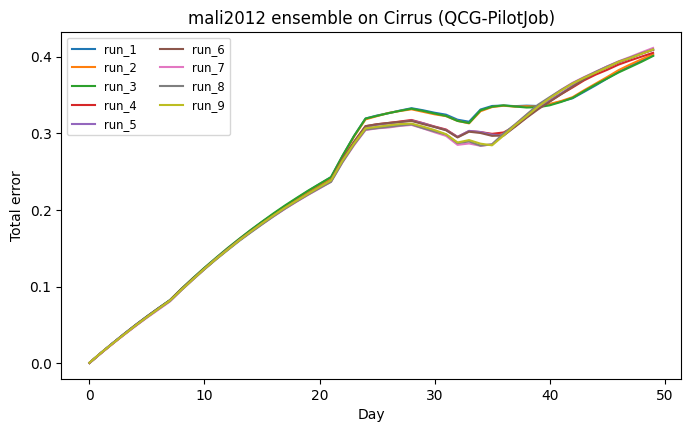

,run,max_move_speed,max_walk_speed,days simulated,final total error
0,run_1,145.1,20.1,50,0.4016
1,run_2,145.1,55.0,50,0.4030
2,run_3,145.1,89.9,50,0.4009
3,run_4,300.0,20.1,50,0.4050
4,run_5,300.0,55.0,50,0.4090
5,run_6,300.0,89.9,50,0.4090
6,run_7,454.9,20.1,50,0.4113
7,run_8,454.9,55.0,50,0.4094
8,run_9,454.9,89.9,50,0.4093


In [54]:
import matplotlib.pyplot as plt
import pandas as pd
import yaml

results_dir = max(
    (FABSIM_ROOT / "results").glob(f"{FLEE_SCENARIO}_cirrus_*"),
    key=lambda path: path.stat().st_mtime,
)
print("Results:", results_dir, "\n")

run_dirs = sorted((results_dir / "RUNS").glob("run_*"), key=lambda run: int(run.name.split("_")[1]))
move_rules = {
    run.name: yaml.safe_load((run / "simsetting.yml").read_text(encoding="utf-8"))["move_rules"]
    for run in run_dirs
}
varied_parameters = [
    name for name in move_rules[run_dirs[0].name]
    if len({rules[name] for rules in move_rules.values()}) > 1
]

rows = []
fig, ax = plt.subplots(figsize=(8, 4.5))

for run in run_dirs:
    out = pd.read_csv(run / "out.csv")
    rows.append({
        "run": run.name,
        **{name: round(move_rules[run.name][name], 1) for name in varied_parameters},
        "days simulated": len(out),
        "final total error": round(out["Total error"].iloc[-1], 4),
    })
    ax.plot(out["Day"], out["Total error"], label=run.name)

ax.set_xlabel("Day")
ax.set_ylabel("Total error")
ax.set_title(f"{FLEE_SCENARIO} ensemble on Cirrus (QCG-PilotJob)")
ax.legend(ncol=2, fontsize="small")
plt.show()

pd.DataFrame(rows)

When you are done for the day, close the background SSH connection from a terminal:

```sh
ssh -O exit cirrus
```